In [1]:
import os
from math import ceil
from typing import Optional

from pyspark.sql import SparkSession, DataFrame
from pyspark import SparkConf
from pyspark.sql import functions as F
from pyspark.sql.functions import col

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter

In [2]:
def create_spark_configuration() -> SparkConf:
    """
    Создает и конфигурирует экземпляр SparkConf для приложения Spark.

    Returns:
        SparkConf: Настроенный экземпляр SparkConf.
    """
    # Получаем имя пользователя
    user_name = os.getenv("USER")

    conf = SparkConf()
    conf.setAppName("lab 1 Glassdoor EDA")
    conf.setMaster("yarn")
    conf.set("spark.submit.deployMode", "client")
    conf.set("spark.executor.memory", "12g")
    conf.set("spark.executor.cores", "8")
    conf.set("spark.executor.instances", "2")
    conf.set("spark.driver.memory", "4g")
    conf.set("spark.driver.cores", "2")
    conf.set("spark.jars.packages", "org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0")
    conf.set("spark.sql.extensions", "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
    conf.set("spark.sql.catalog.spark_catalog", "org.apache.iceberg.spark.SparkCatalog")
    conf.set("spark.sql.catalog.spark_catalog.type", "hadoop")
    conf.set("spark.sql.catalog.spark_catalog.warehouse", f"hdfs:///user/{user_name}/warehouse")
    conf.set("spark.sql.catalog.spark_catalog.io-impl", "org.apache.iceberg.hadoop.HadoopFileIO")

    return conf

In [3]:
conf = create_spark_configuration()

In [4]:
spark = SparkSession.builder.config(conf=conf).getOrCreate()
spark

:: loading settings :: url = jar:file:/opt/spark-3.5.2-bin-hadoop3/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/user0/.ivy2/cache
The jars for the packages stored in: /home/user0/.ivy2/jars
org.apache.iceberg#iceberg-spark-runtime-3.5_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-4df36ce3-de85-4c33-8605-b1429cc822c2;1.0
	confs: [default]
	found org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 in central
:: resolution report :: resolve 597ms :: artifacts dl 25ms
	:: modules in use:
	org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   1   |   0   |   0   |   0   ||   1   |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spa

In [5]:
MAIN_COLOR = "#2a78d6"     # основной цвет столбцов и линий
SECOND_COLOR = "#eb6834"   # второй цвет — для сравнения «до» и «после»
NEGATIVE_COLOR = "#c23b3b" # отрицательные значения корреляции
LIGHT_COLOR = "#cde2fb"    # заливка ящиков на диаграммах размаха
DARK_COLOR = "#184f95"     # медианы на диаграммах размаха
TEXT_COLOR = "#52514e"     # подписи значений на графиках

DIVERGING_CMAP = LinearSegmentedColormap.from_list(
    "blue_gray_red", ["#1c5cab", "#f0efec", "#c23b3b"]
)

sns.set_theme(
    style="whitegrid",
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#c3c2b7",
        "grid.color": "#e6e5e1",
        "axes.titleweight": "bold",
    },
)

# Разделитель разрядов: 1 234 567
thousands = FuncFormatter(lambda value, _: f"{value:,.0f}".replace(",", " "))

In [6]:
database_name = "orlov_database"
spark.catalog.setCurrentDatabase(database_name)

In [7]:
df = spark.table("glassdoor_reviews").cache()

In [8]:
df.show(5)

+---------------+-----------+--------------------+--------------------+---------------+------------+--------------+----------+----------+----------+----------+-------------+-----------+-----------------+--------------+-------------------+--------------+----------+----------+------------+
|           firm|date_review|           job_title|             current|employee_status|tenure_years|overall_rating| recommend|ceo_approv|   outlook|career_opp|comp_benefits|senior_mgmt|work_life_balance|culture_values|diversity_inclusion|headline_words|pros_words|cons_words|advice_words|
+---------------+-----------+--------------------+--------------------+---------------+------------+--------------+----------+----------+----------+----------+-------------+-----------+-----------------+--------------+-------------------+--------------+----------+----------+------------+
|     McDonald s| 2019-05-14|         Crew Member|Current Employee,...|        Current|           3|             4|  Positive|      M

In [9]:
df.printSchema()

root
 |-- firm: string (nullable = true)
 |-- date_review: date (nullable = true)
 |-- job_title: string (nullable = true)
 |-- current: string (nullable = true)
 |-- employee_status: string (nullable = true)
 |-- tenure_years: integer (nullable = true)
 |-- overall_rating: integer (nullable = true)
 |-- recommend: string (nullable = true)
 |-- ceo_approv: string (nullable = true)
 |-- outlook: string (nullable = true)
 |-- career_opp: double (nullable = true)
 |-- comp_benefits: double (nullable = true)
 |-- senior_mgmt: double (nullable = true)
 |-- work_life_balance: double (nullable = true)
 |-- culture_values: double (nullable = true)
 |-- diversity_inclusion: double (nullable = true)
 |-- headline_words: integer (nullable = true)
 |-- pros_words: integer (nullable = true)
 |-- cons_words: integer (nullable = true)
 |-- advice_words: integer (nullable = true)



In [10]:
rows_initial = df.count()
rows_initial

9901889

In [11]:
def describe_columns(data: DataFrame):
    distinct = data.agg(
        *[F.approx_count_distinct(c).alias(c) for c in data.columns]
    ).first()

    return pd.DataFrame(
        {
            "Тип Spark": [t for _, t in data.dtypes],
            "Уникальных значений (≈)": [distinct[c] for c in data.columns],
        },
        index=data.columns,
    )

In [12]:
describe_columns(df)

26/10/10 15:37:21 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


,Тип Spark,Уникальных значений (≈)
firm,string,33128
date_review,date,5447
job_title,string,458094
current,string,94
employee_status,string,2
tenure_years,int,6
overall_rating,int,5
recommend,string,3
ceo_approv,string,4
outlook,string,4


In [13]:
df = df.drop("current")

In [14]:
duplicates = (
    df
    .groupBy(df.columns)
    .count()
    .where(col("count") > 1)
)

print("Групп повторяющихся строк:", duplicates.count())
duplicates.orderBy(F.desc("count")).show(5)

Групп повторяющихся строк: 609412


+--------------------+-----------+--------------------+---------------+------------+--------------+----------+----------+----------+----------+-------------+-----------+-----------------+--------------+-------------------+--------------+----------+----------+------------+-----+
|                firm|date_review|           job_title|employee_status|tenure_years|overall_rating| recommend|ceo_approv|   outlook|career_opp|comp_benefits|senior_mgmt|work_life_balance|culture_values|diversity_inclusion|headline_words|pros_words|cons_words|advice_words|count|
+--------------------+-----------+--------------------+---------------+------------+--------------+----------+----------+----------+----------+-------------+-----------+-----------------+--------------+-------------------+--------------+----------+----------+------------+-----+
|Continental Softw...| 2020-09-14|Customer Care Man...|        Current|           3|             5|  Positive|No opinion|  Positive|       5.0|          5.0|      

In [15]:
df_dedup = df.dropDuplicates().cache()
rows_dedup = df_dedup.count()
df.unpersist()
df = df_dedup

removed = rows_initial - rows_dedup
print(f"Удалено дубликатов: {removed} ({100 * removed / rows_initial:.2f}%)")
print(f"Осталось строк: {rows_dedup}")

Удалено дубликатов: 846660 (8.55%)
Осталось строк: 9055229


Создадим функцию для поиска пропуска во всех столбцах сразу

In [16]:
def null_report(data: DataFrame) -> pd.DataFrame:
    """
    Подсчет количества и доли NULL-значений во всех столбцах.

    Args:
        data (DataFrame): DataFrame, содержащий данные.

    Returns:
        pd.DataFrame: Таблица с числом и долей пропусков по столбцам.
    """
    row = data.agg(
        F.count("*").alias("__total__"),
        *[F.sum(col(c).isNull().cast("int")).alias(c) for c in data.columns]
    ).first()

    total = row["__total__"]
    report = pd.DataFrame(
        {"Пропусков": [row[c] or 0 for c in data.columns]},
        index=data.columns,
    )
    report["Доля, %"] = (100 * report["Пропусков"] / total).round(2)
    return report.sort_values("Доля, %", ascending=False)


def plot_null_report(report: pd.DataFrame) -> None:
    """
    Построение горизонтальной столбчатой диаграммы долей пропусков.

    Args:
        report (pd.DataFrame): Результат функции null_report.

    Returns:
        None
    """
    report = report[report["Пропусков"] > 0]
    if report.empty:
        print("Пропущенных значений нет")
        return

    report = report.iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, 0.45 * len(report) + 1.5))
    ax.barh(report.index, report["Доля, %"], color=MAIN_COLOR, height=0.6)
    for y, value in enumerate(report["Доля, %"]):
        ax.text(value + 1, y, f"{value:.1f}%", va="center",
                fontsize=9, color=TEXT_COLOR)
    ax.set_xlim(0, 110)
    ax.set_xlabel("Доля пропусков, %")
    ax.set_title("Доля пропущенных значений по признакам")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()

In [17]:
missing = null_report(df)
missing

,Пропусков,"Доля, %"
advice_words,9055216,100.00
diversity_inclusion,6005171,66.32
tenure_years,3607694,39.84
culture_values,2050990,22.65
senior_mgmt,1859603,20.54
comp_benefits,1823010,20.13
work_life_balance,1821642,20.12
career_opp,1759948,19.44
job_title,629606,6.95
headline_words,35971,0.40


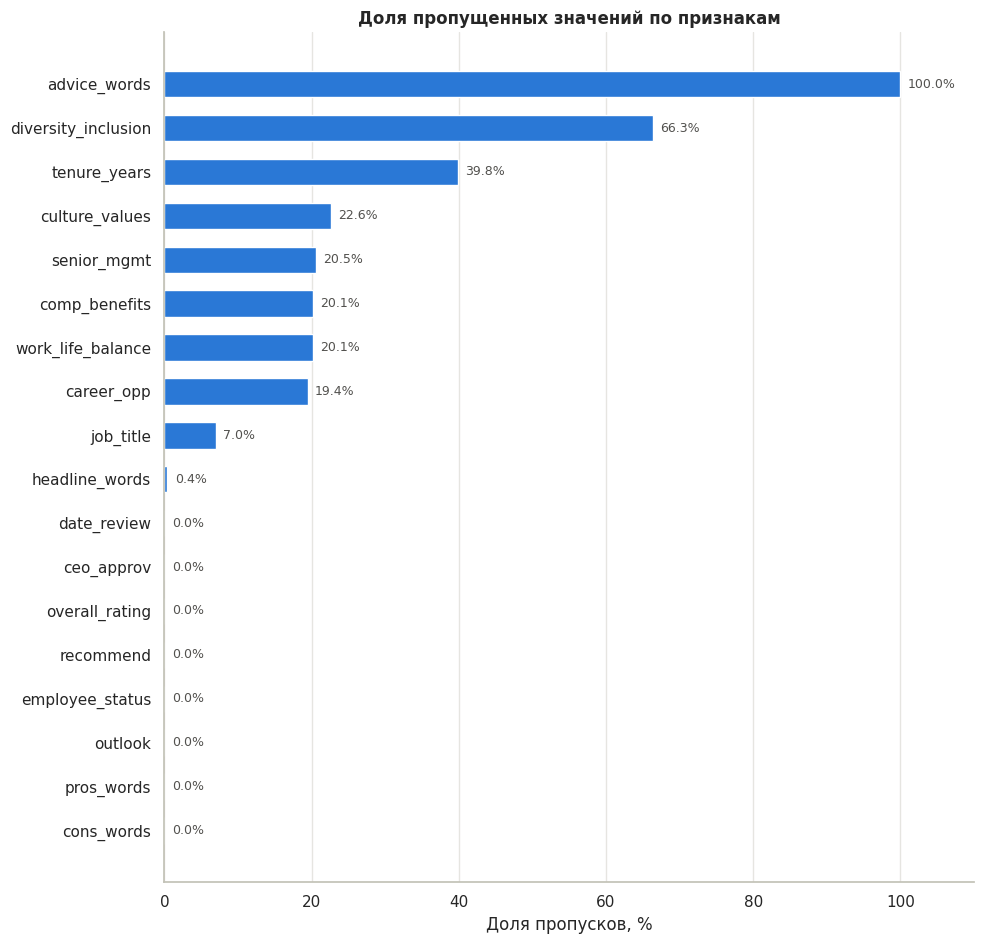

In [18]:
plot_null_report(missing)

Обрабатывать пропуски будем по следующим правилам:
1. строки без ключевых признаков (`firm`, `date_review`, `overall_rating`) удаляем: без компании, даты или общей оценки отзыв не имеет смысла для анализа;
2. в категориальных признаках заменяем пропуски отдельной категорией `Unknown`;
3. количественный признак с долей пропусков больше 50% удаляем целиком
4. в остальных количественных признаках заменяем пропуски медианой. 
5. пропуск в длине текста означает, что автор ничего не написал, поэтому заменяем его нулём.


In [19]:
def count_nulls(data: DataFrame, column_name: str) -> float:
    """
    Подсчет количества NULL-значений в указанном столбце.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        column_name (str): Имя столбца.

    Returns:
        float: Доля пропусков в процентах.
    """
    row = data.agg(
        F.sum(col(column_name).isNull().cast("int")).alias("nulls"),
        F.count("*").alias("total"),
    ).first()

    nulls = row["nulls"] or 0
    percent = 100 * nulls / row["total"] if row["total"] else 0.0
    print(f"Число строк с NULL в столбце {column_name}: {nulls} ({percent:.2f}%)")
    return percent


def fill_or_drop_numeric(data: DataFrame,
                         column_name: str,
                         drop_threshold: float = 50.0) -> tuple[DataFrame, str]:
    """
    Обработка пропусков в количественном признаке: удаление признака,
    если пропусков больше порога, иначе заполнение медианой.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        column_name (str): Имя столбца.
        drop_threshold (float): Порог доли пропусков в процентах.

    Returns:
        tuple[DataFrame, str]: Новый DataFrame и выполненное действие
        ("dropped", "median" или "none").
    """
    null_percent = count_nulls(data, column_name)

    if null_percent > drop_threshold:
        print(f"Пропусков больше {drop_threshold:.0f}% — удаляем признак {column_name}")
        return data.drop(column_name), "dropped"

    if null_percent > 0:
        median_value = data.approxQuantile(column_name, [0.5], 0.001)[0]
        print(f"Заполняем пропуски медианой: {median_value:g}")
        return data.fillna({column_name: median_value}), "median"

    print("Пропусков нет")
    return data, "none"

Выполним корреляцию до заполенния пропусков, тк заполнение пропусков медианой меняет взаимосвязи между признаками


In [20]:
def compute_correlation_matrix(data: DataFrame,
                               columns: list[str]) -> pd.DataFrame:
    """
    Вычисляет матрицу корреляций Пирсона для указанных столбцов
    за один проход по данным.

    Args:
        data (DataFrame): DataFrame PySpark.
        columns (list[str]): Список столбцов.

    Returns:
        pd.DataFrame: Корреляционная матрица.
    """
    pairs = [(a, b) for i, a in enumerate(columns) for b in columns[i + 1:]]
    row = data.agg(
        *[F.corr(a, b).alias(f"{a}__{b}") for a, b in pairs]
    ).first()

    matrix = pd.DataFrame(1.0, index=columns, columns=columns)
    for a, b in pairs:
        value = row[f"{a}__{b}"]
        matrix.loc[a, b] = matrix.loc[b, a] = np.nan if value is None else value
    return matrix


def plot_correlation_matrix(matrix: pd.DataFrame, title: str) -> None:
    """
    Визуализирует корреляционную матрицу в виде тепловой карты.

    Args:
        matrix (pd.DataFrame): Корреляционная матрица.
        title (str): Заголовок графика.

    Returns:
        None
    """
    size = max(6, 0.7 * len(matrix) + 2)
    plt.figure(figsize=(size + 1.5, size))
    # Округление и + 0.0 убирают «-0.00» в подписях
    sns.heatmap(
        matrix.round(2) + 0.0, annot=True, fmt=".2f", cmap=DIVERGING_CMAP,
        vmin=-1, vmax=1, center=0, square=True,
        linewidths=2, linecolor="white",
        annot_kws={"size": 9},
        cbar_kws={"shrink": 0.8, "label": "Коэффициент корреляции Пирсона"},
    )
    plt.title(title)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


def compute_and_visualize_correlation_matrix(data: DataFrame,
                                             columns: list[str],
                                             title: str = "Корреляционная матрица") -> pd.DataFrame:
    """
    Вычисляет и визуализирует корреляционную матрицу для указанных
    колонок в DataFrame PySpark.

    Args:
        data (DataFrame): DataFrame PySpark.
        columns (list[str]): Список колонок для вычисления корреляции.
        title (str): Заголовок графика.

    Returns:
        pd.DataFrame: Корреляционная матрица.
    """
    matrix = compute_correlation_matrix(data, columns)
    plot_correlation_matrix(matrix, title)
    return matrix

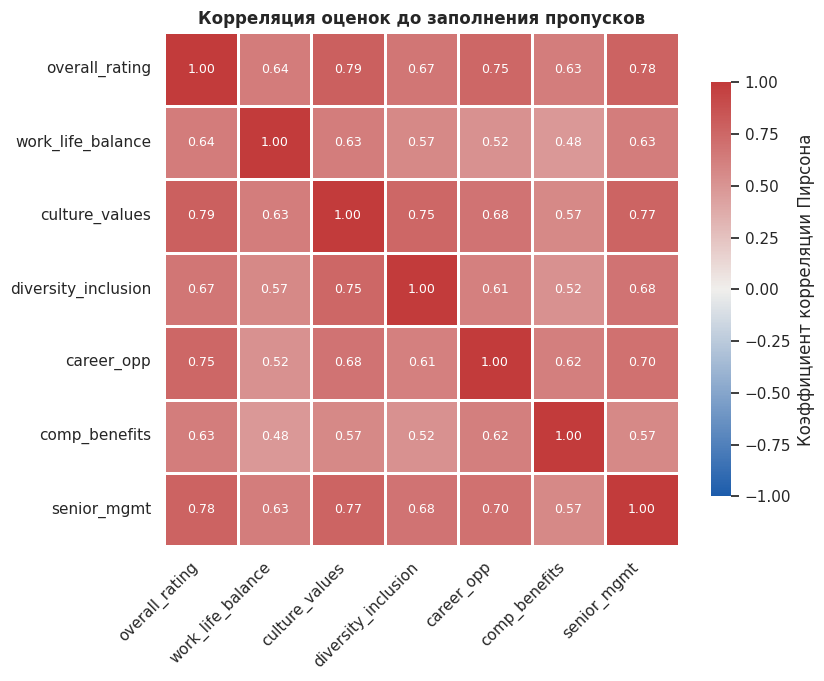

In [21]:
RATING_COLUMNS = [
    "overall_rating", "work_life_balance", "culture_values",
    "diversity_inclusion", "career_opp", "comp_benefits", "senior_mgmt"
]

corr_before = compute_and_visualize_correlation_matrix(
    data=df, columns=RATING_COLUMNS,
    title="Корреляция оценок до заполнения пропусков"
)

Создадим функции для расчёта и визуализации распределений категориальных признаков, средних значений целевого признака по категориям, статистических показателей с диаграммой «ящик с усами» и гистограмм количественных признаков.


In [22]:
def _order_categories(present: list, order: Optional[list]) -> list:
    """Возвращает категории в заданном порядке, добавляя в конец непредусмотренные."""
    if order is None:
        return present
    known = [o for o in order if o in present]
    return known + [p for p in present if p not in known]


def plot_cat_distribution(data: DataFrame,
                          column_name: str,
                          top_n: int = 20,
                          order: Optional[list] = None,
                          sort_by_value: bool = False,
                          horizontal: bool = False,
                          title: Optional[str] = None) -> None:
    """
    Построение распределения категориального признака.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        column_name (str): Имя столбца для группировки.
        top_n (int): Количество самых частых категорий для отображения.
        order (Optional[list]): Явный порядок категорий (для признаков с малым
            числом категорий).
        sort_by_value (bool): Сортировать по значению категории, а не по частоте.
        horizontal (bool): Горизонтальные столбцы (для длинных названий).
        title (Optional[str]): Заголовок графика.

    Returns:
        None
    """
    categories = data.groupBy(column_name).count()
    total = categories.agg(F.sum("count")).first()[0]
    print(f"Количество категорий признака {column_name}: {categories.count()}")

    if order is not None or sort_by_value:
        pdf = categories.orderBy(column_name).toPandas()
        if order is not None:
            ordered = _order_categories(list(pdf[column_name]), order)
            pdf = pdf.set_index(column_name).loc[ordered].reset_index()
    else:
        pdf = categories.orderBy(F.desc("count")).limit(top_n).toPandas()

    pdf["Доля, %"] = (100 * pdf["count"] / total).round(2)
    labels = pdf[column_name].map(lambda v: "NULL" if v is None else f"{v:g}"
                                  if isinstance(v, float) else str(v))

    if horizontal:
        fig, ax = plt.subplots(figsize=(10, 0.35 * len(pdf) + 1.5))
        ax.barh(labels[::-1], pdf["count"][::-1], color=MAIN_COLOR, height=0.7)
        ax.xaxis.set_major_formatter(thousands)
        ax.set_xlabel("Количество отзывов")
        ax.grid(axis="y", visible=False)
    else:
        fig, ax = plt.subplots(figsize=(10, 5))
        ax.bar(labels, pdf["count"], color=MAIN_COLOR, width=0.7)
        ax.yaxis.set_major_formatter(thousands)
        ax.set_ylabel("Количество отзывов")
        ax.set_xlabel(column_name)
        ax.grid(axis="x", visible=False)
        if len(pdf) > 8:
            plt.xticks(rotation=45, ha="right")

    ax.set_title(title or f"Распределение признака {column_name}")
    plt.tight_layout()
    plt.show()
    display(pdf.rename(columns={"count": "Количество"}))


def plot_mean_by_category(data: DataFrame,
                          column_name: str,
                          value_column: str = "overall_rating",
                          top_n: int = 20,
                          order: Optional[list] = None,
                          horizontal: bool = False) -> None:
    """
    Построение средних значений количественного признака по категориям.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        column_name (str): Категориальный признак.
        value_column (str): Количественный признак, среднее которого считается.
        top_n (int): Количество самых частых категорий (если не задан order).
        order (Optional[list]): Явный порядок категорий.
        horizontal (bool): Горизонтальные столбцы (для длинных названий).

    Returns:
        None
    """
    stats = (
        data
        .groupBy(column_name)
        .agg(F.mean(value_column).alias("Среднее"),
             F.count("*").alias("Количество"))
    )

    if order is not None:
        pdf = stats.toPandas()
        ordered = _order_categories(list(pdf[column_name]), order)
        pdf = pdf.set_index(column_name).loc[ordered].reset_index()
    else:
        pdf = stats.orderBy(F.desc("Количество")).limit(top_n).toPandas()

    labels = pdf[column_name].astype(str)
    means = pdf["Среднее"]

    if horizontal:
        fig, ax = plt.subplots(figsize=(10, 0.35 * len(pdf) + 1.5))
        ax.barh(labels[::-1], means[::-1], color=MAIN_COLOR, height=0.7)
        for y, value in enumerate(means[::-1]):
            ax.text(value + 0.05, y, f"{value:.2f}", va="center",
                    fontsize=9, color=TEXT_COLOR)
        ax.set_xlim(0, 5.5)
        ax.set_xlabel(f"Среднее значение {value_column}")
        ax.grid(axis="y", visible=False)
    else:
        fig, ax = plt.subplots(figsize=(10, 5))
        ax.bar(labels, means, color=MAIN_COLOR, width=0.6)
        for x, value in enumerate(means):
            ax.text(x, value + 0.08, f"{value:.2f}", ha="center",
                    fontsize=9, color=TEXT_COLOR)
        ax.set_ylim(0, 5.5)
        ax.set_ylabel(f"Среднее значение {value_column}")
        ax.set_xlabel(column_name)
        ax.grid(axis="x", visible=False)
        if len(pdf) > 8:
            plt.xticks(rotation=45, ha="right")

    ax.set_title(f"Среднее значение {value_column} по категориям {column_name}")
    plt.tight_layout()
    plt.show()
    display(pdf.round(3))

In [23]:
def plot_boxplots(data: DataFrame,
                  columns: list[str],
                  sample_fraction: float = 0.1,
                  title: str = "Диаграммы размаха") -> None:
    """
    Расчет статистических показателей и построение boxplot для
    нескольких столбцов в PySpark DataFrame.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        columns (list of str): Список имен столбцов для построения boxplot.
        sample_fraction (float): Доля данных для семплирования выбросов.
        title (str): Заголовок графика.

    Returns:
        None
    """
    box_data = []
    stats = {}

    for column in columns:
        # Вычисление квантилей
        q1, median, q3 = data.approxQuantile(column, [0.25, 0.5, 0.75], 0.01)

        # Вычисление IQR и границ усов
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        # Минимум, среднее, СКО и максимум — одним заданием
        agg = data.agg(
            F.min(column).alias("min"), F.mean(column).alias("mean"),
            F.stddev(column).alias("std"), F.max(column).alias("max"),
            F.count(column).alias("count"),
        ).first()

        outliers_df = data.filter(
            (col(column) < lower_bound) | (col(column) > upper_bound)
        )
        outliers_count = outliers_df.count()

        # Ограничение усов минимальным и максимальным значениями
        whislo = max(lower_bound, agg["min"])
        whishi = min(upper_bound, agg["max"])

        # Семплирование выбросов для отображения на графике
        outliers = []
        if outliers_count > 0:
            outliers = [
                row[column] for row in
                outliers_df.sample(sample_fraction).select(column).limit(1000).collect()
            ]
            # Добавление минимального и максимального значений, если они
            # относятся к выбросам и не присутствуют в семпле
            if agg["min"] < lower_bound and agg["min"] not in outliers:
                outliers.append(agg["min"])
            if agg["max"] > upper_bound and agg["max"] not in outliers:
                outliers.append(agg["max"])

        box_data.append({
            "whislo": whislo,   # Нижняя граница усов
            "q1": q1,           # Первый квартиль
            "med": median,      # Медиана
            "q3": q3,           # Третий квартиль
            "whishi": whishi,   # Верхняя граница усов
            "fliers": outliers  # Выбросы
        })

        stats[column] = {
            "Минимум": agg["min"],
            "Среднее": agg["mean"],
            "СКО": agg["std"],
            "Q1": q1,
            "Медиана": median,
            "Q3": q3,
            "Максимум": agg["max"],
            "Нижняя граница": lower_bound,
            "Верхняя граница": upper_bound,
            "Выбросов": outliers_count,
            "Доля выбросов, %": 100 * outliers_count / agg["count"] if agg["count"] else 0,
        }

    # Вывод статистических характеристик
    display(pd.DataFrame(stats).T.round(2))

    # Построение boxplot
    fig, ax = plt.subplots(figsize=(14, 1.1 * len(columns) + 1.5))
    ax.bxp(
        box_data, vert=False, positions=range(1, len(columns) + 1),
        widths=0.5, patch_artist=True,
        boxprops={"facecolor": LIGHT_COLOR, "edgecolor": MAIN_COLOR},
        medianprops={"color": DARK_COLOR, "linewidth": 2},
        whiskerprops={"color": MAIN_COLOR},
        capprops={"color": MAIN_COLOR},
        flierprops={"marker": "o", "markersize": 4, "markeredgecolor": "none",
                    "markerfacecolor": MAIN_COLOR, "alpha": 0.4},
    )
    ax.set_yticks(range(1, len(columns) + 1))
    ax.set_yticklabels(columns)
    ax.set_xlabel("Значение")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def plot_quant_distribution(data: DataFrame,
                            column: str,
                            num_bins: int = 100,
                            title: Optional[str] = None) -> None:
    """
    Построение гистограммы для количественной переменной.
    Разбиение на интервалы и подсчёт выполняются в Spark,
    в pandas передаются только итоговые счётчики.

    Args:
        data (DataFrame): DataFrame с данными.
        column (str): Название колонки с количественной переменной.
        num_bins (int): Количество бинов для гистограммы.
        title (Optional[str]): Заголовок графика.

    Returns:
        None
    """
    data = data.filter(col(column).isNotNull())

    # Находим минимальное и максимальное значения колонки
    row = data.agg(F.min(column).alias("min"), F.max(column).alias("max")).first()
    min_value, max_value = row["min"], row["max"]

    # Размер бина. Для целочисленного признака с небольшим размахом
    # используем один бин на каждое значение, иначе появятся пустые бины
    is_integer = dict(data.dtypes)[column] in ("int", "bigint", "smallint", "tinyint")
    if is_integer and max_value - min_value < num_bins:
        bin_size = 1
    else:
        bin_size = (max_value - min_value) / num_bins or 1

    # Номер бина для каждой строки, затем количество строк в каждом бине
    bin_counts = (
        data
        .withColumn("bin", F.floor((col(column) - min_value) / bin_size))
        .groupBy("bin")
        .count()
        .toPandas()
    )

    # Левые границы бинов
    bin_counts["bin_start"] = min_value + bin_counts["bin"] * bin_size

    plt.figure(figsize=(14, 5))
    plt.bar(bin_counts["bin_start"], bin_counts["count"], width=bin_size * 0.9,
            align="edge" if not is_integer or bin_size != 1 else "center",
            color=MAIN_COLOR)
    plt.gca().yaxis.set_major_formatter(thousands)
    plt.grid(axis="x", visible=False)
    plt.xlabel(column)
    plt.ylabel("Количество отзывов")
    plt.title(title or f"Распределение количественного признака {column}")
    plt.tight_layout()
    plt.show()

1-ый признак - Фирма

In [24]:
count_nulls(data=df, column_name="firm");

Число строк с NULL в столбце firm: 0 (0.00%)


Количество категорий признака firm: 34374


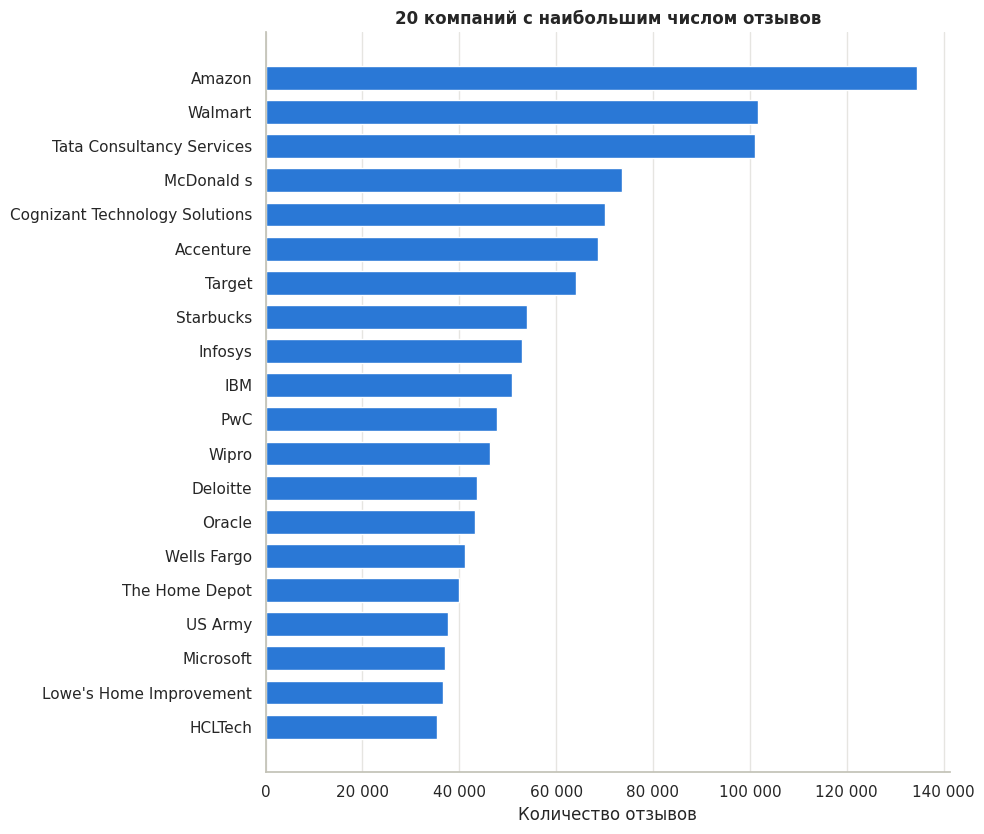

,firm,Количество,"Доля, %"
0,Amazon,134603,1.49
1,Walmart,101785,1.12
2,Tata Consultancy Services,100968,1.12
3,McDonald s,73502,0.81
4,Cognizant Technology Solutions,70075,0.77
5,Accenture,68599,0.76
6,Target,64093,0.71
7,Starbucks,54061,0.60
8,Infosys,52938,0.58
9,IBM,50834,0.56


In [25]:
plot_cat_distribution(data=df, column_name="firm", horizontal=True,
                      title="20 компаний с наибольшим числом отзывов")

Посмотрим, как распределено число отзывов на одну компанию.

In [26]:
reviews_per_firm = df.groupBy("firm").count()
(
    reviews_per_firm
    .select(col("count").alias("reviews_per_firm"))
    .summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max")
    .show()
)

+-------+------------------+
|summary|  reviews_per_firm|
+-------+------------------+
|  count|             34374|
|   mean|263.43250712748005|
| stddev|1947.8945935836334|
|    min|                 1|
|    25%|                 2|
|    50%|                 8|
|    75%|                53|
|    max|            134603|
+-------+------------------+



Перейдем к признаку - дате отзыва
Проверим наличие пропусков и допустимость значений: сайт Glassdoor начал публиковать отзывы в 2008 году, а дата отзыва не может быть позже текущей.

In [27]:
count_nulls(data=df, column_name="date_review");

Число строк с NULL в столбце date_review: 145 (0.00%)


In [28]:
min_date = F.lit("2008-01-01").cast("date")

bad_dates = df.filter(
    col("date_review").isNull()
    | (col("date_review") < min_date)
    | (col("date_review") > F.current_date())
)
print("Строк с пустой или недопустимой датой:", bad_dates.count())

df.agg(F.min("date_review").alias("Первая дата"),
       F.max("date_review").alias("Последняя дата")).show()

Строк с пустой или недопустимой датой: 145


+-----------+--------------+
|Первая дата|Последняя дата|
+-----------+--------------+
| 2008-01-25|    2023-07-26|
+-----------+--------------+



Удалим строки с пустой или недопустимой датой и выделим из даты количественный признак `year` — год публикации отзыва.

In [29]:
df = (
    df
    .filter(col("date_review").between(min_date, F.current_date()))
    .withColumn("year", F.year("date_review"))
)
count_nulls(data=df, column_name="date_review");

Число строк с NULL в столбце date_review: 0 (0.00%)


Признак overall_rating

Целевой признак — общая оценка работодателя по шкале от 1 до 5. Признак **порядковый**, в расчётах рассматривается как **количественный** дискретный. Проверим наличие пропусков и значений вне шкалы.

In [30]:
count_nulls(data=df, column_name="overall_rating");
print("Значений вне шкалы 1–5:",
      df.filter(~col("overall_rating").between(1, 5)).count())

Число строк с NULL в столбце overall_rating: 0 (0.00%)


Значений вне шкалы 1–5: 0


Строки без общей оценки и со значениями вне шкалы удаляем: это целевой признак, заполнять его искусственными значениями нельзя.

In [31]:
df = df.filter(col("overall_rating").between(1, 5))
count_nulls(data=df, column_name="overall_rating");

Число строк с NULL в столбце overall_rating: 0 (0.00%)


Количество категорий признака overall_rating: 5


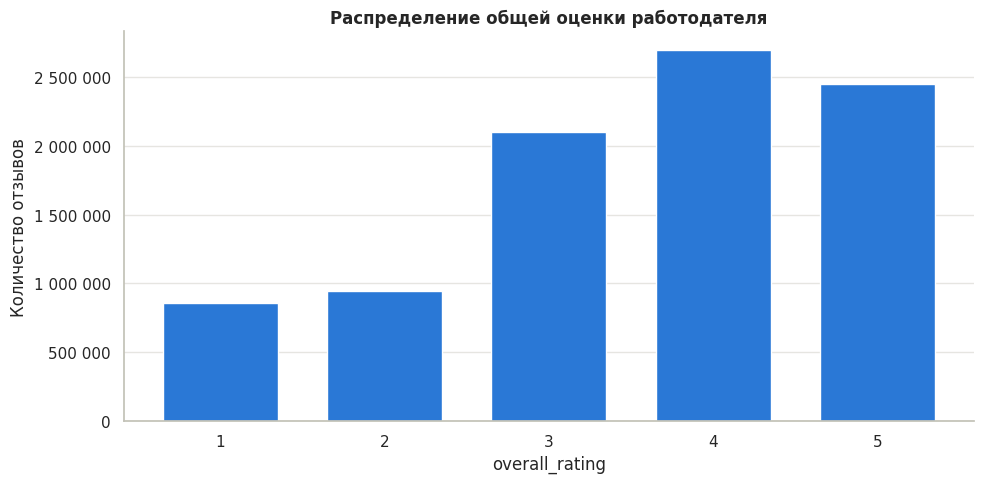

,overall_rating,Количество,"Доля, %"
0,1,858941,9.49
1,2,944830,10.43
2,3,2102638,23.22
3,4,2697489,29.79
4,5,2451186,27.07


In [32]:
plot_cat_distribution(data=df, column_name="overall_rating", sort_by_value=True,
                      title="Распределение общей оценки работодателя")

,Минимум,Среднее,СКО,Q1,Медиана,Q3,Максимум,Нижняя граница,Верхняя граница,Выбросов,"Доля выбросов, %"
overall_rating,1.0,3.55,1.25,3.0,4.0,5.0,5.0,0.0,8.0,0.0,0.0


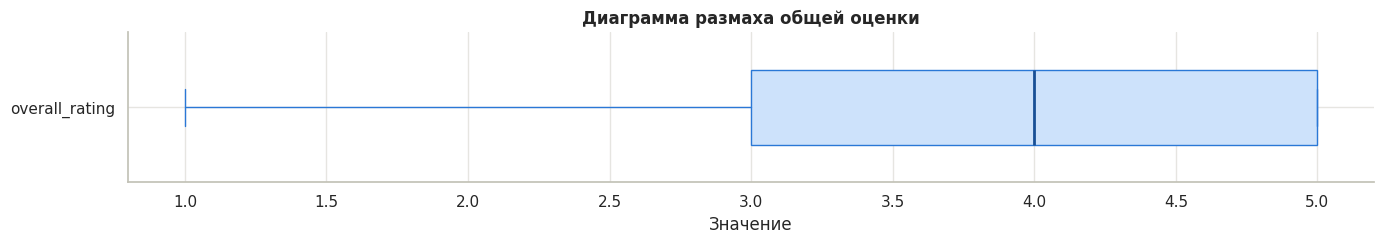

In [33]:
plot_boxplots(data=df, columns=["overall_rating"],
              title="Диаграмма размаха общей оценки")

Посмотрим, как менялись число отзывов и средняя оценка по годам.

In [34]:
def plot_reviews_by_year(data: DataFrame,
                         value_column: str = "overall_rating") -> None:
    """
    Построение количества отзывов и среднего значения признака по годам.
    Две величины разного масштаба показаны на двух отдельных графиках
    с общей осью годов.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        value_column (str): Признак, среднее которого считается.

    Returns:
        None
    """
    pdf = (
        data
        .groupBy("year")
        .agg(F.count("*").alias("Количество"),
             F.mean(value_column).alias("Среднее"))
        .orderBy("year")
        .toPandas()
    )

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    ax1.bar(pdf["year"], pdf["Количество"], color=MAIN_COLOR, width=0.7)
    ax1.yaxis.set_major_formatter(thousands)
    ax1.set_ylabel("Количество отзывов")
    ax1.set_title("Количество отзывов по годам")
    ax1.grid(axis="x", visible=False)

    ax2.plot(pdf["year"], pdf["Среднее"], color=MAIN_COLOR,
             linewidth=2, marker="o", markersize=8)
    ax2.set_ylabel(f"Среднее значение {value_column}")
    ax2.set_title(f"Среднее значение {value_column} по годам")
    ax2.set_xticks(pdf["year"])
    ax2.tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()
    display(pdf.round(3))

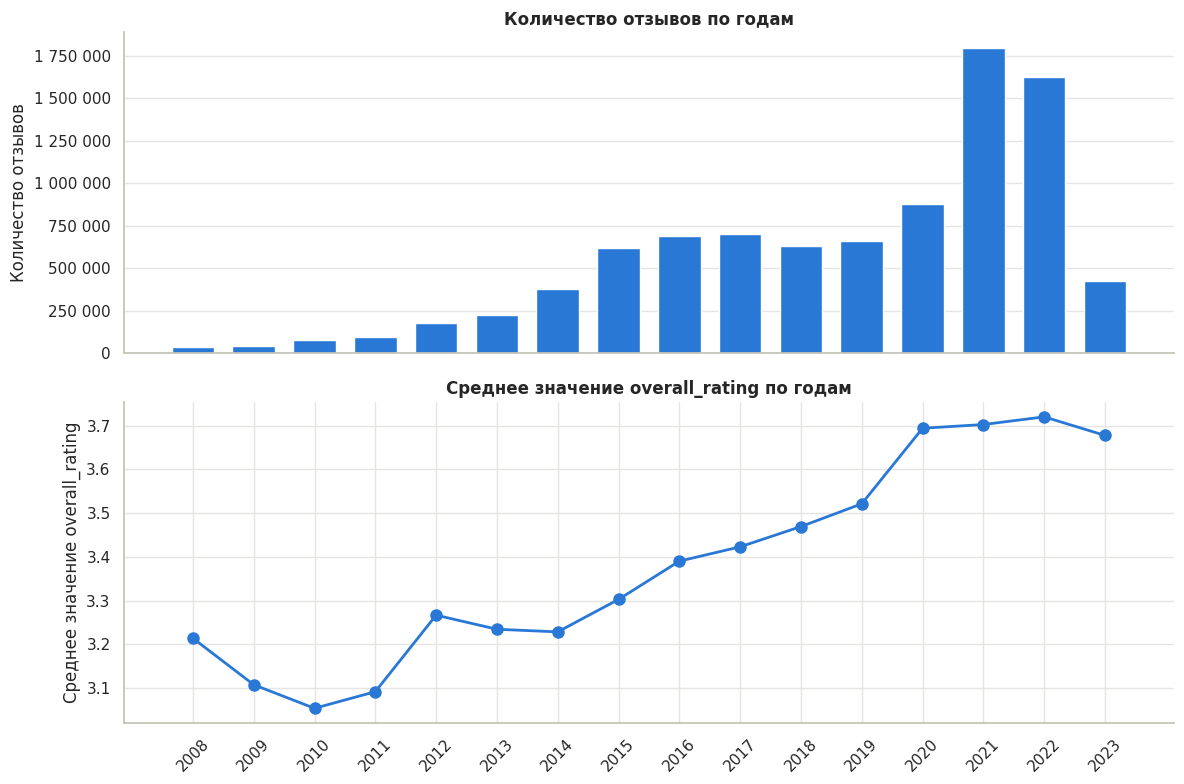

,year,Количество,Среднее
0,2008,34983,3.214
1,2009,39549,3.108
2,2010,75947,3.054
3,2011,96920,3.092
4,2012,175649,3.267
5,2013,225956,3.234
6,2014,374647,3.228
7,2015,617408,3.303
8,2016,690854,3.390
9,2017,702377,3.423


In [35]:
plot_reviews_by_year(data=df)

##### Подоценки: `work_life_balance`, `culture_values`, `diversity_inclusion`, `career_opp`, `comp_benefits`, `senior_mgmt`

Признаки порядковые (шкала 1–5), в расчётах рассматриваются как количественные. Подоценки необязательны для заполнения, поэтому в них много пропусков. Обработаем каждую по правилу: при доле пропусков больше 50% признак удаляется, иначе пропуски заполняются медианой.

Перед обработкой сохраним ссылку на текущий датафрейм, чтобы потом сравнить распределения до и после заполнения.

In [36]:
SUBRATING_COLUMNS = RATING_COLUMNS[1:]

df_before_fill = df
imputed_columns = []

for column in SUBRATING_COLUMNS:
    print(f"--- {column}")
    df, action = fill_or_drop_numeric(data=df, column_name=column)
    if action == "median":
        imputed_columns.append(column)
    print()

--- work_life_balance


Число строк с NULL в столбце work_life_balance: 1821497 (20.12%)


Заполняем пропуски медианой: 4

--- culture_values


Число строк с NULL в столбце culture_values: 2050845 (22.65%)


Заполняем пропуски медианой: 4

--- diversity_inclusion


...

Заполняем пропуски медианой: 3

--- comp_benefits


Число строк с NULL в столбце comp_benefits: 1822865 (20.13%)


Заполняем пропуски медианой: 3

--- senior_mgmt


Число строк с NULL в столбце senior_mgmt: 1859458 (20.53%)


Заполняем пропуски медианой: 3



Сравним распределения подоценок до заполнения (только реально выставленные оценки) и после заполнения медианой.

In [37]:
def plot_imputation_effect(before: DataFrame,
                           after: DataFrame,
                           columns: list[str]) -> None:
    """
    Сравнение распределений дискретных признаков до и после
    заполнения пропусков.

    Args:
        before (DataFrame): Данные до заполнения пропусков.
        after (DataFrame): Данные после заполнения пропусков.
        columns (list[str]): Список признаков.

    Returns:
        None
    """
    if not columns:
        print("Нет признаков, в которых заполнялись пропуски")
        return

    ncols = min(3, len(columns))
    nrows = ceil(len(columns) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.8 * nrows),
                             squeeze=False)

    for ax, column in zip(axes.flat, columns):
        b = before.filter(col(column).isNotNull()).groupBy(column).count().toPandas()
        a = after.groupBy(column).count().toPandas()
        values = sorted(set(b[column]) | set(a[column]))
        b_share = b.set_index(column)["count"].reindex(values, fill_value=0)
        a_share = a.set_index(column)["count"].reindex(values, fill_value=0)
        b_share = 100 * b_share / b_share.sum()
        a_share = 100 * a_share / a_share.sum()

        x = np.arange(len(values))
        width = 0.38
        ax.bar(x - width / 2 - 0.01, b_share, width=width, color=MAIN_COLOR,
               label="До заполнения (только известные значения)")
        ax.bar(x + width / 2 + 0.01, a_share, width=width, color=SECOND_COLOR,
               label="После заполнения медианой")
        ax.set_xticks(x)
        ax.set_xticklabels([f"{v:g}" for v in values])
        ax.set_title(column)
        ax.set_ylabel("Доля отзывов, %")
        ax.grid(axis="x", visible=False)

    for ax in list(axes.flat)[len(columns):]:
        ax.axis("off")

    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.suptitle("Распределение подоценок до и после заполнения пропусков",
                 fontweight="bold", y=0.995)
    fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False,
               bbox_to_anchor=(0.5, 0.96))
    plt.tight_layout(rect=(0, 0, 1, 0.90))
    plt.show()

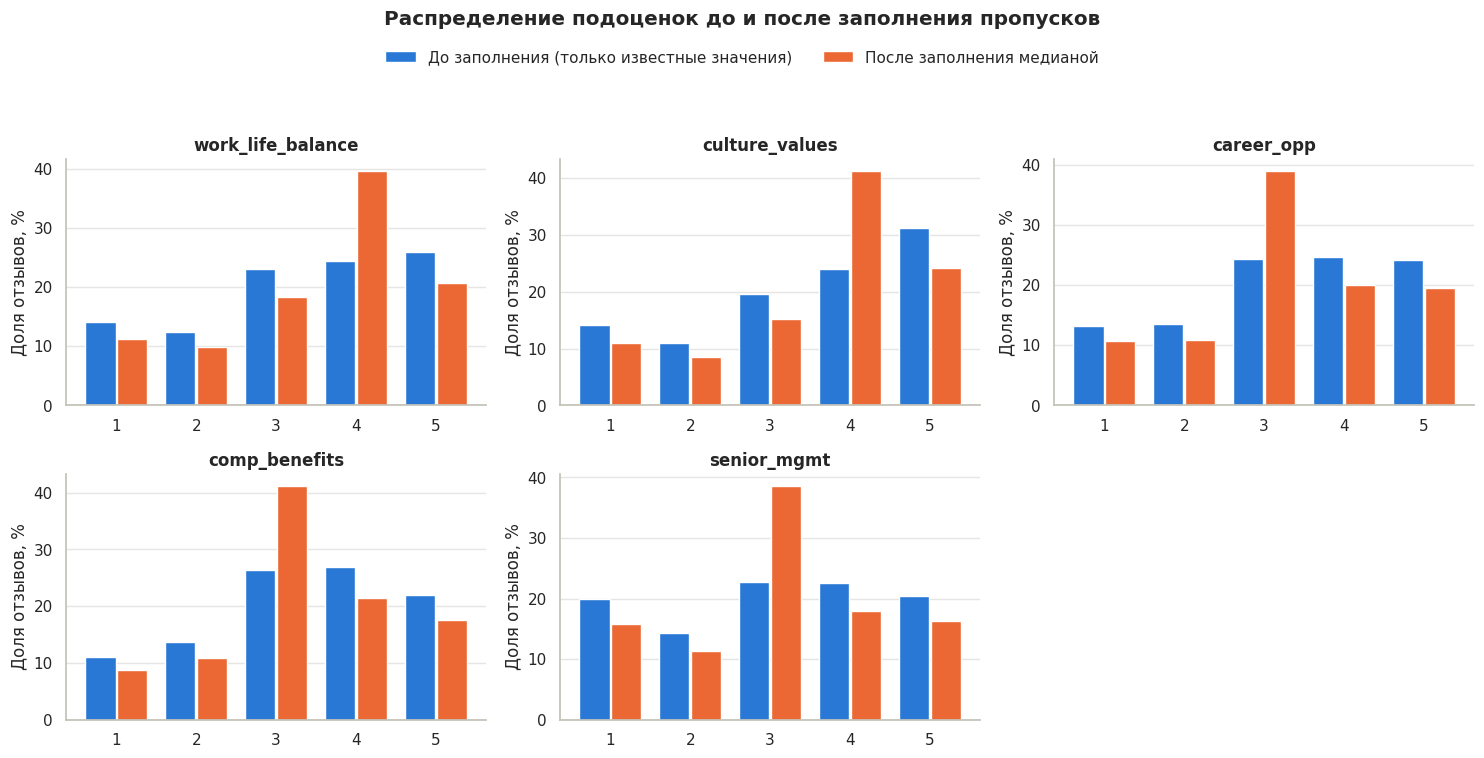

In [38]:
plot_imputation_effect(before=df_before_fill, after=df, columns=imputed_columns)

Заполнение медианой увеличивает долю медианного значения шкалы и уменьшает разброс признака. Это известный недостаток заполнения константой. Альтернативой было бы заполнять подоценку общей оценкой того же отзыва: подоценки сильно коррелируют с общей оценкой (см. корреляционную матрицу выше). Но такой способ искусственно усилил бы связь подоценок с общей оценкой, поэтому для разведочного анализа выбрано более нейтральное заполнение медианой.

Рассчитаем статистические показатели оставшихся подоценок и построим диаграммы размаха.

,Минимум,Среднее,СКО,Q1,Медиана,Q3,Максимум,Нижняя граница,Верхняя граница,Выбросов,"Доля выбросов, %"
work_life_balance,1.0,3.49,1.24,3.0,4.0,4.0,5.0,1.5,5.5,1019835.0,11.26
culture_values,1.0,3.59,1.24,3.0,4.0,4.0,5.0,1.5,5.5,987554.0,10.91
career_opp,1.0,3.27,1.20,3.0,3.0,4.0,5.0,1.5,5.5,963399.0,10.64
comp_benefits,1.0,3.28,1.14,3.0,3.0,4.0,5.0,1.5,5.5,795439.0,8.78
senior_mgmt,1.0,3.07,1.25,2.0,3.0,4.0,5.0,-1.0,7.0,0.0,0.00


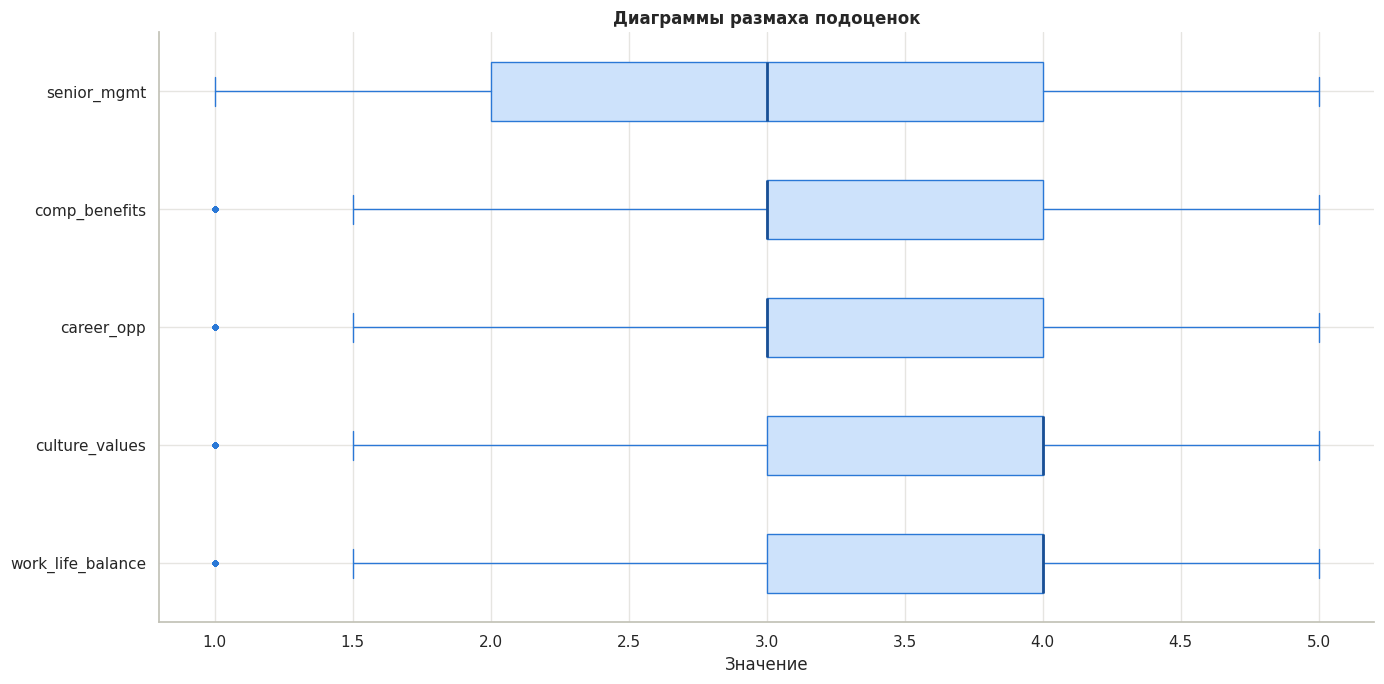

In [39]:
subratings_left = [c for c in SUBRATING_COLUMNS if c in df.columns]
plot_boxplots(data=df, columns=subratings_left,
              title="Диаграммы размаха подоценок")

Как и для общей оценки, все значения подоценок лежат в пределах шкалы 1–5, поэтому ошибочных значений нет. После заполнения медианой у части подоценок межквартильный размах сужается, и метод IQR может отнести к выбросам минимальную оценку 1. Это допустимое значение шкалы, а не аномалия, поэтому такие строки не удаляем.

Признаки `recommend`, `ceo_approv`, `outlook`

In [40]:
OPINION_COLUMNS = ["recommend", "ceo_approv", "outlook"]
OPINION_ORDER = ["Positive", "Mild", "Negative", "No opinion", "Unknown"]

for column in OPINION_COLUMNS:
    count_nulls(data=df, column_name=column)

df = df.fillna({column: "Unknown" for column in OPINION_COLUMNS})

Число строк с NULL в столбце recommend: 0 (0.00%)


Число строк с NULL в столбце ceo_approv: 0 (0.00%)


Число строк с NULL в столбце outlook: 0 (0.00%)


Количество категорий признака recommend: 3


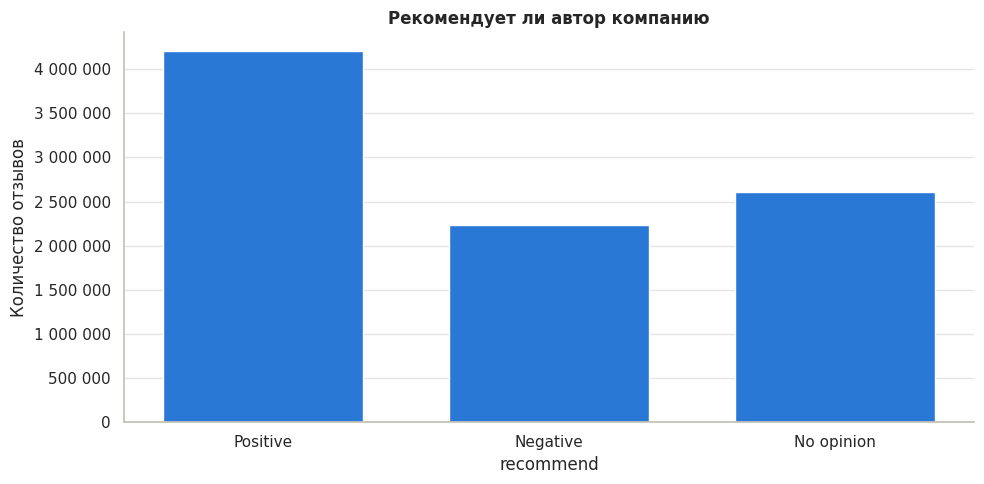

,recommend,Количество,"Доля, %"
0,Positive,4206061,46.45
1,Negative,2239493,24.73
2,No opinion,2609530,28.82


In [41]:
plot_cat_distribution(data=df, column_name="recommend", order=OPINION_ORDER,
                      title="Рекомендует ли автор компанию")

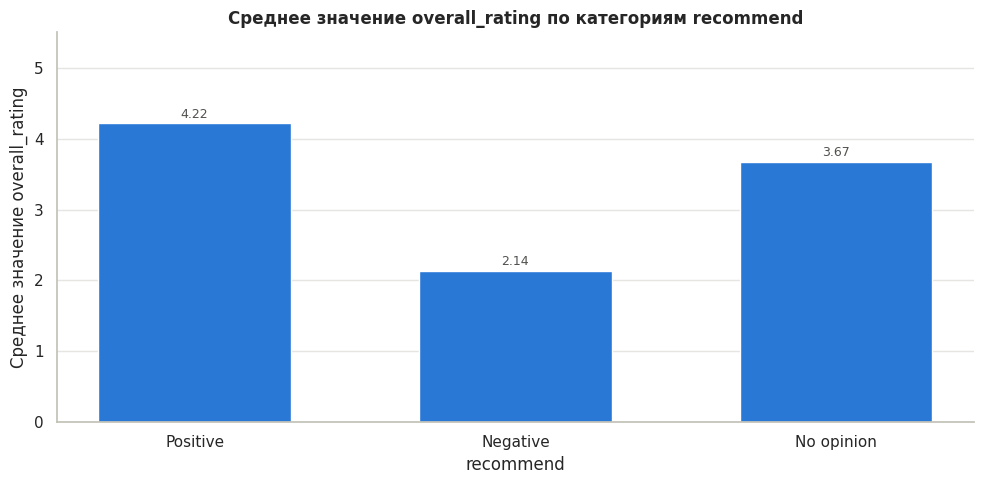

,recommend,Среднее,Количество
0,Positive,4.217,4206061
1,Negative,2.138,2239493
2,No opinion,3.670,2609530


In [42]:
plot_mean_by_category(data=df, column_name="recommend", order=OPINION_ORDER)

Количество категорий признака ceo_approv: 4


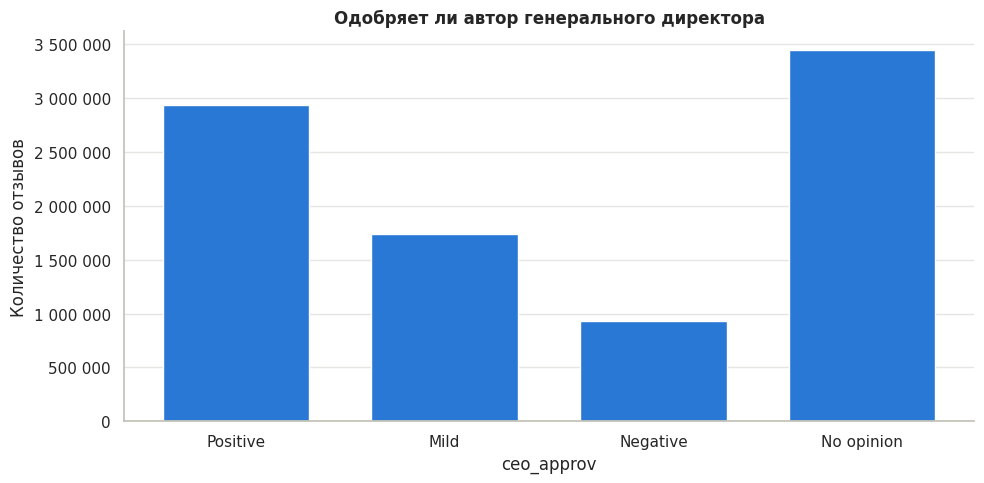

,ceo_approv,Количество,"Доля, %"
0,Positive,2939512,32.46
1,Mild,1740427,19.22
2,Negative,928966,10.26
3,No opinion,3446179,38.06


In [43]:
plot_cat_distribution(data=df, column_name="ceo_approv", order=OPINION_ORDER,
                      title="Одобряет ли автор генерального директора")

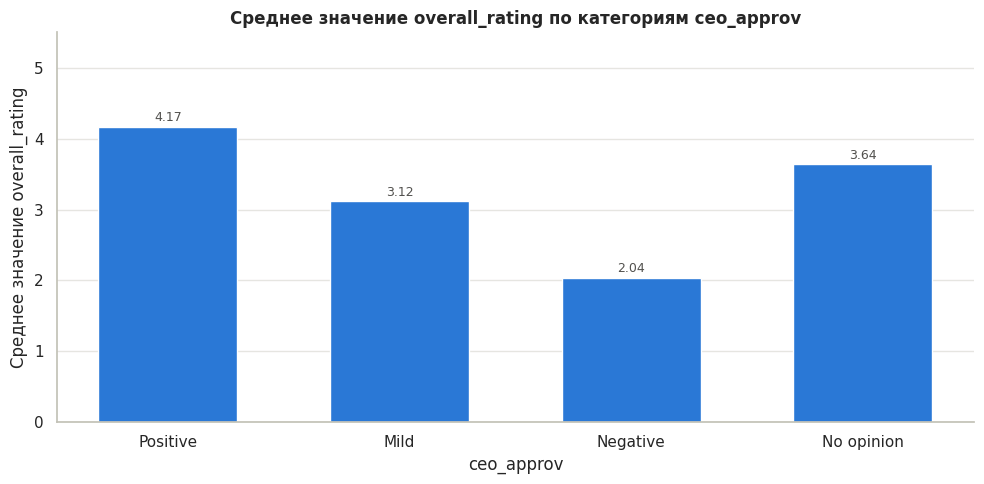

,ceo_approv,Среднее,Количество
0,Positive,4.167,2939512
1,Mild,3.116,1740427
2,Negative,2.038,928966
3,No opinion,3.638,3446179


In [44]:
plot_mean_by_category(data=df, column_name="ceo_approv", order=OPINION_ORDER)

Количество категорий признака outlook: 4


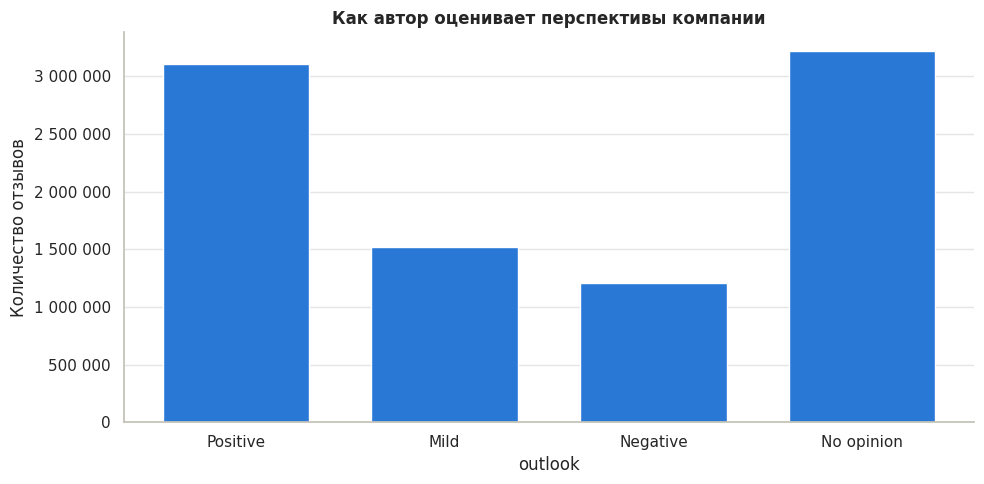

,outlook,Количество,"Доля, %"
0,Positive,3105735,34.30
1,Mild,1521374,16.80
2,Negative,1208873,13.35
3,No opinion,3219102,35.55


In [45]:
plot_cat_distribution(data=df, column_name="outlook", order=OPINION_ORDER,
                      title="Как автор оценивает перспективы компании")

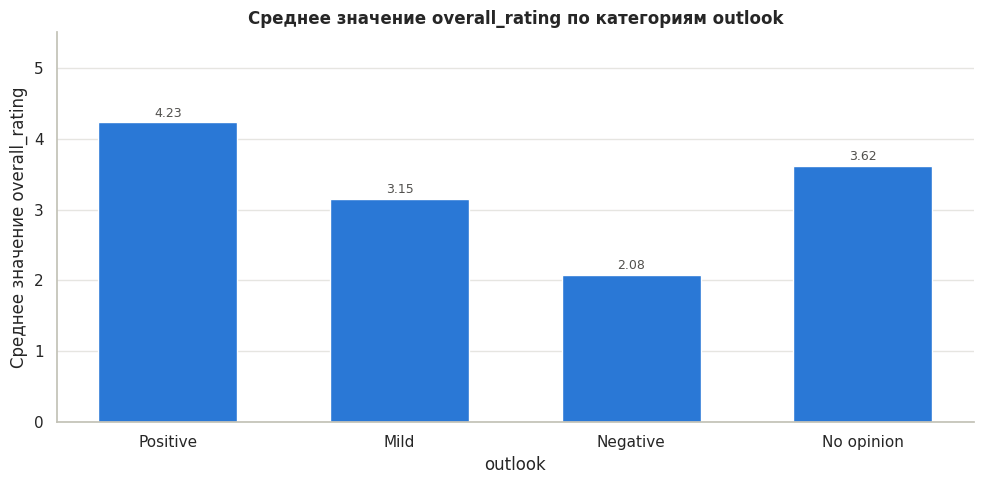

,outlook,Среднее,Количество
0,Positive,4.232,3105735
1,Mild,3.150,1521374
2,Negative,2.081,1208873
3,No opinion,3.619,3219102


In [46]:
plot_mean_by_category(data=df, column_name="outlook", order=OPINION_ORDER)

Признак employee_status

Признак бинарный категориальный: текущий (Current) или бывший (Former) сотрудник. Пропуски возникают, если статус не указан или указан в нестандартной форме. Заменим их категорией Unknown.

In [47]:
count_nulls(data=df, column_name="employee_status")
df = df.fillna({"employee_status": "Unknown"})

Число строк с NULL в столбце employee_status: 94 (0.00%)


Количество категорий признака employee_status: 3


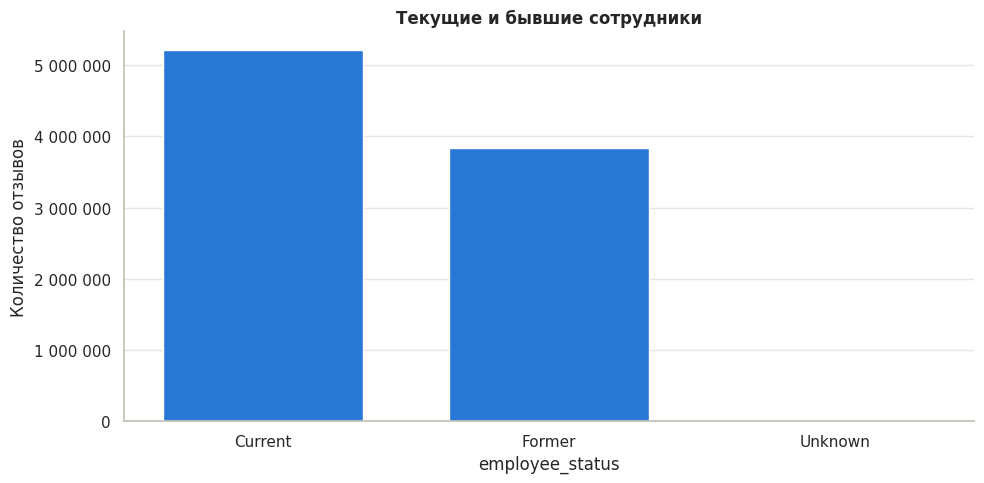

,employee_status,Количество,"Доля, %"
0,Current,5214825,57.59
1,Former,3840165,42.41
2,Unknown,94,0.00


In [48]:
plot_cat_distribution(data=df, column_name="employee_status",
                      order=["Current", "Former", "Unknown"],
                      title="Текущие и бывшие сотрудники")

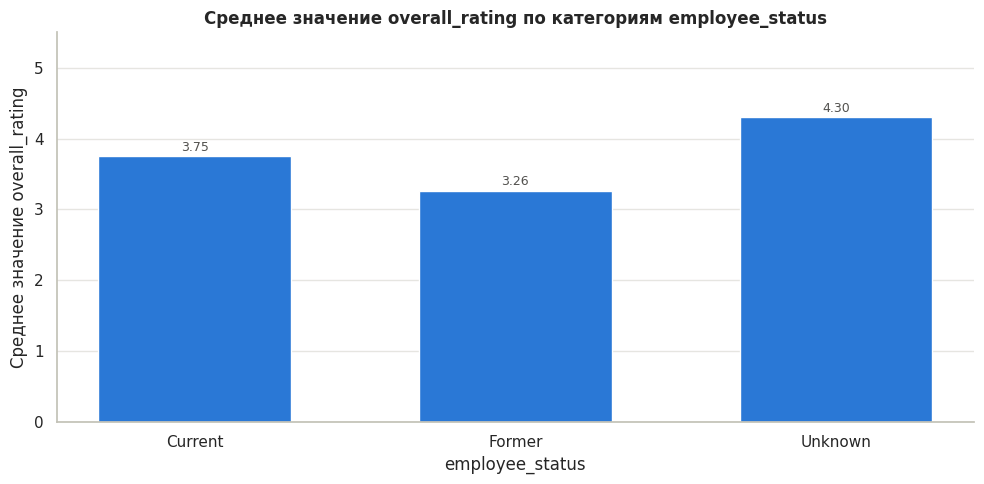

,employee_status,Среднее,Количество
0,Current,3.752,5214825
1,Former,3.265,3840165
2,Unknown,4.298,94


In [49]:
plot_mean_by_category(data=df, column_name="employee_status",
                      order=["Current", "Former", "Unknown"])

Признак tenure_years

Признак количественный дискретный: нижняя граница стажа в годах. Значения образуют интервалы (менее 1 года, более 1, 3, 5, 8, 10 лет), поэтому для визуализации удобно представить стаж категориальным признаком `tenure_group`, в котором пропуски станут категорией `Unknown`. Сам количественный признак обработаем по общему правилу.

In [50]:
TENURE_ORDER = ["<1", "1+", "3+", "5+", "8+", "10+", "Unknown"]

df = df.withColumn(
    "tenure_group",
    F.when(col("tenure_years").isNull(), "Unknown")
     .when(col("tenure_years") == 0, "<1")
     .otherwise(F.concat(col("tenure_years").cast("string"), F.lit("+")))
)

Количество категорий признака tenure_group: 7


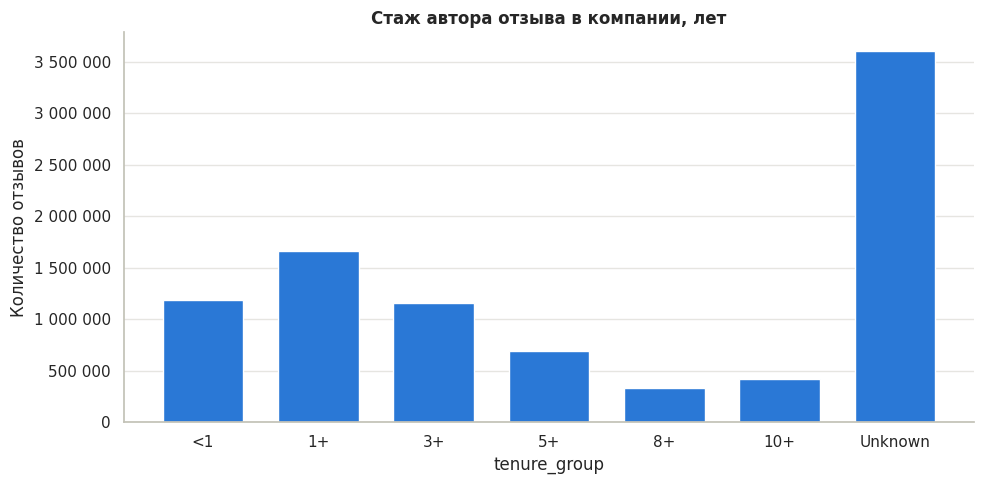

,tenure_group,Количество,"Доля, %"
0,<1,1190066,13.14
1,1+,1662440,18.36
2,3+,1156604,12.77
3,5+,688691,7.61
4,8+,328987,3.63
5,10+,420747,4.65
6,Unknown,3607549,39.84


In [51]:
plot_cat_distribution(data=df, column_name="tenure_group", order=TENURE_ORDER,
                      title="Стаж автора отзыва в компании, лет")

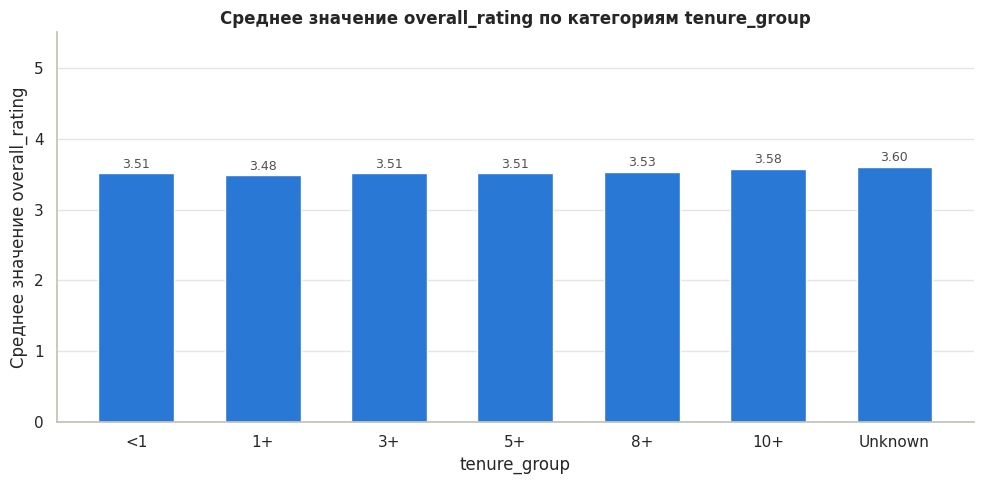

,tenure_group,Среднее,Количество
0,<1,3.510,1190066
1,1+,3.483,1662440
2,3+,3.509,1156604
3,5+,3.511,688691
4,8+,3.534,328987
5,10+,3.579,420747
6,Unknown,3.600,3607549


In [52]:
plot_mean_by_category(data=df, column_name="tenure_group", order=TENURE_ORDER)

In [53]:
df, tenure_action = fill_or_drop_numeric(data=df, column_name="tenure_years")

Число строк с NULL в столбце tenure_years: 3607549 (39.84%)


Заполняем пропуски медианой: 1


Признак job_title

Признак **категориальный** с очень большим числом категорий. Авторы, скрывающие должность, обозначены значением `Anonymous Employee`: по сути это тоже пропуск. Посчитаем такие значения, заменим их на `NULL`, а затем все пропуски — на `Unknown`.

In [54]:
anonymous = df.filter(col("job_title") == "Anonymous Employee").count()
print("Значений Anonymous Employee:", anonymous)

df = df.withColumn(
    "job_title",
    F.when(col("job_title") == "Anonymous Employee", None)
     .otherwise(col("job_title"))
)
count_nulls(data=df, column_name="job_title")
df = df.fillna({"job_title": "Unknown"})

Значений Anonymous Employee: 1567716


Число строк с NULL в столбце job_title: 2197177 (24.26%)


Количество категорий признака job_title: 435789


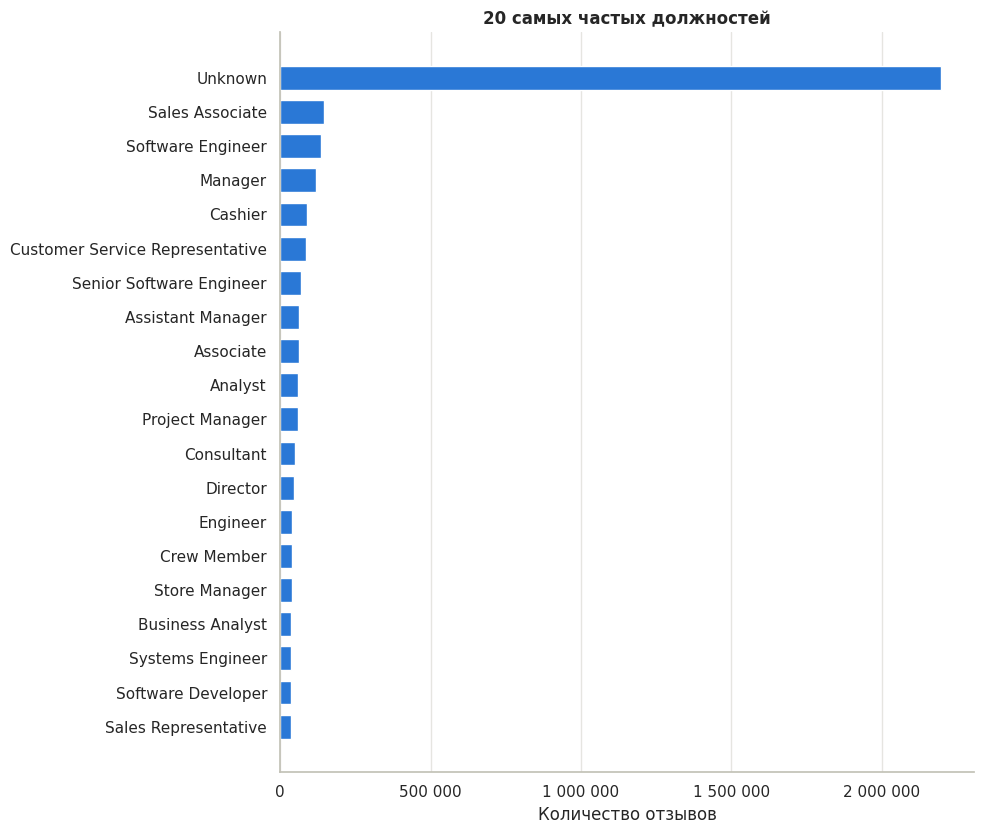

,job_title,Количество,"Доля, %"
0,Unknown,2197190,24.26
1,Sales Associate,146720,1.62
2,Software Engineer,135749,1.50
3,Manager,119738,1.32
4,Cashier,90260,1.00
5,Customer Service Representative,86605,0.96
6,Senior Software Engineer,70364,0.78
7,Assistant Manager,63406,0.70
8,Associate,63381,0.70
9,Analyst,59794,0.66


In [55]:
plot_cat_distribution(data=df, column_name="job_title", horizontal=True,
                      title="20 самых частых должностей")

Признаки `headline_words`, `pros_words`, `cons_words`, `advice_words`

Признаки количественные дискретные: длина заголовка, текстов «плюсы» и «минусы» и совета руководству в словах. Пропуск означает, что текст не написан, поэтому заменяем его нулём. Совет руководству — необязательное поле, поэтому у большинства отзывов его длина окажется равной нулю.

In [56]:
WORD_COLUMNS = ["headline_words", "pros_words", "cons_words", "advice_words"]

for column in WORD_COLUMNS:
    count_nulls(data=df, column_name=column)

df = df.fillna({column: 0 for column in WORD_COLUMNS})

Число строк с NULL в столбце headline_words: 35826 (0.40%)


Число строк с NULL в столбце pros_words: 14 (0.00%)


Число строк с NULL в столбце cons_words: 60 (0.00%)


Число строк с NULL в столбце advice_words: 9055071 (100.00%)


,Минимум,Среднее,СКО,Q1,Медиана,Q3,Максимум,Нижняя граница,Верхняя граница,Выбросов,"Доля выбросов, %"
headline_words,0.0,3.79,3.10,2.0,3.0,5.0,328.0,-2.5,9.5,498026.0,5.50
pros_words,0.0,14.47,19.28,6.0,8.0,15.0,3153.0,-7.5,28.5,915116.0,10.11
cons_words,0.0,21.62,41.58,6.0,9.0,20.0,7019.0,-15.0,41.0,991827.0,10.95
advice_words,0.0,0.00,0.02,0.0,0.0,0.0,44.0,0.0,0.0,13.0,0.00


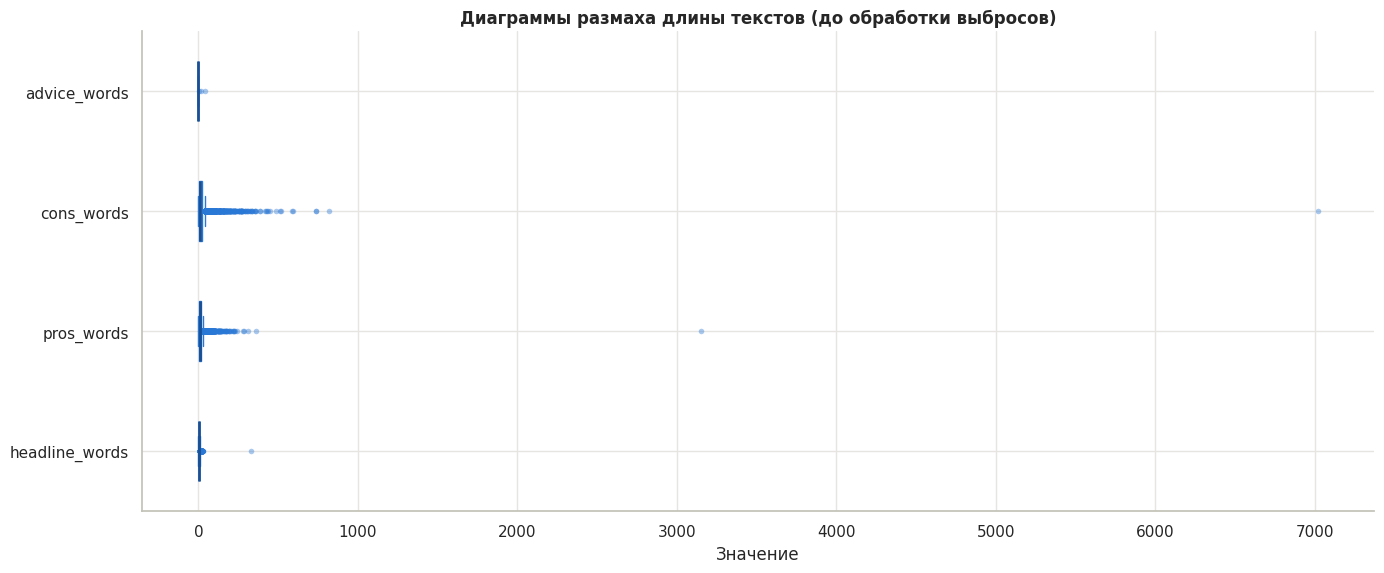

In [57]:
plot_boxplots(data=df, columns=WORD_COLUMNS,
              title="Диаграммы размаха длины текстов (до обработки выбросов)")

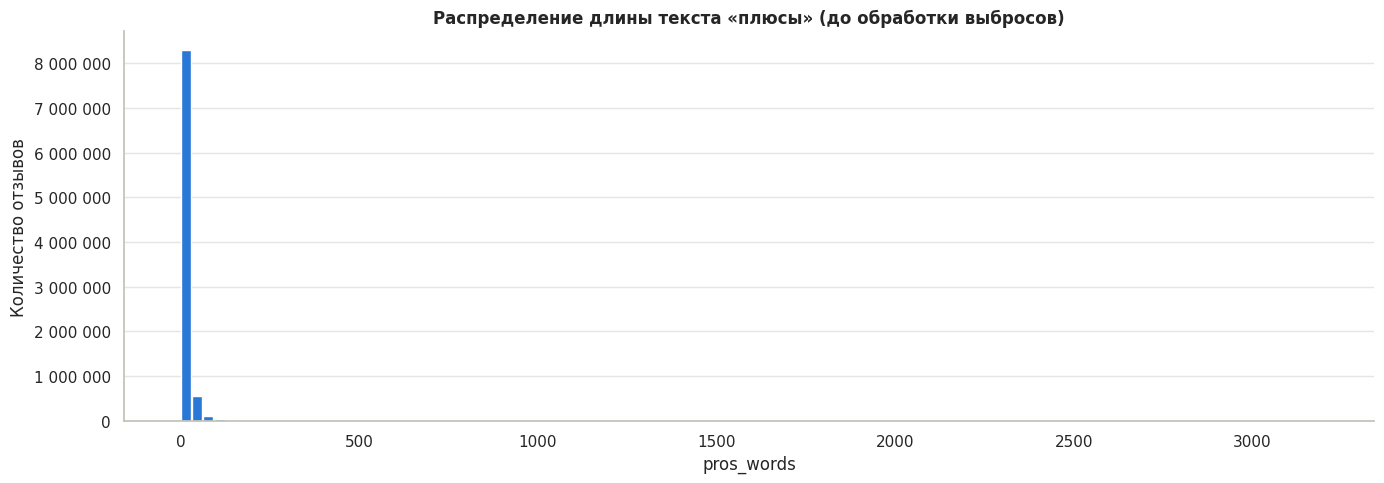

In [58]:
plot_quant_distribution(data=df, column="pros_words",
                        title="Распределение длины текста «плюсы» (до обработки выбросов)")

Наблюдаем сильно скошенное вправо распределение с длинным хвостом: большинство текстов короткие, но встречаются отдельные очень длинные отзывы. Граница по методу IQR для такого распределения слишком строгая — она отнесла бы к выбросам заметную долю обычных отзывов. Поэтому ограничим значения сверху 99-м перцентилем (винзоризация): значения выше него заменяются самим перцентилем. Строки при этом не удаляются, а 1% самых длинных текстов перестаёт искажать среднее и масштаб графиков.

In [59]:
def cap_upper_outliers(data: DataFrame,
                       column_name: str,
                       quantile: float = 0.99) -> DataFrame:
    """
    Ограничение значений признака сверху заданным перцентилем.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        column_name (str): Имя столбца.
        quantile (float): Перцентиль, по которому ограничиваются значения.

    Returns:
        DataFrame: DataFrame с ограниченными значениями.
    """
    cap = int(data.approxQuantile(column_name, [quantile], 0.001)[0])
    affected = data.filter(col(column_name) > cap).count()
    print(f"{column_name}: граница {cap}, изменено значений: {affected}")
    return data.withColumn(column_name, F.least(col(column_name), F.lit(cap)))

In [60]:
for column in WORD_COLUMNS:
    df = cap_upper_outliers(data=df, column_name=column)

headline_words: граница 16, изменено значений: 79024


pros_words: граница 87, изменено значений: 98317


cons_words: граница 182, изменено значений: 98882


advice_words: граница 0, изменено значений: 13


,Минимум,Среднее,СКО,Q1,Медиана,Q3,Максимум,Нижняя граница,Верхняя граница,Выбросов,"Доля выбросов, %"
headline_words,0.0,3.76,2.95,2.0,3.0,5.0,16.0,-2.5,9.5,498026.0,5.50
pros_words,0.0,13.91,14.24,6.0,8.0,15.0,87.0,-7.5,28.5,915116.0,10.11
cons_words,0.0,20.26,28.79,6.0,9.0,20.0,182.0,-15.0,41.0,991827.0,10.95
advice_words,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00


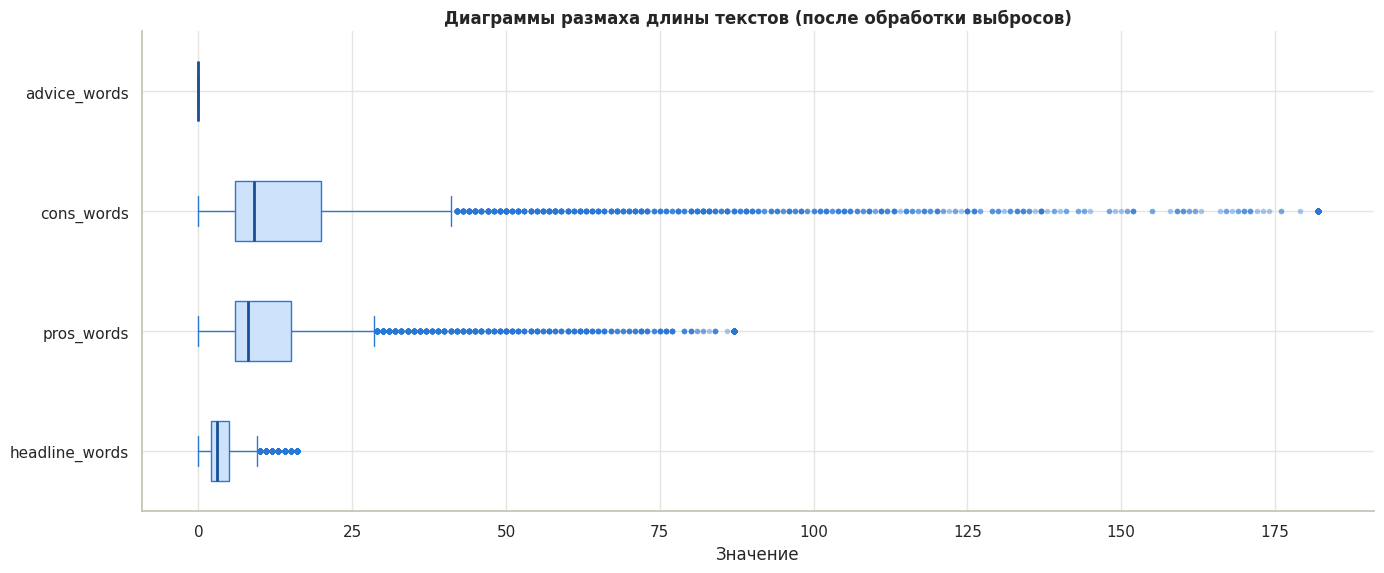

In [61]:
plot_boxplots(data=df, columns=WORD_COLUMNS,
              title="Диаграммы размаха длины текстов (после обработки выбросов)")

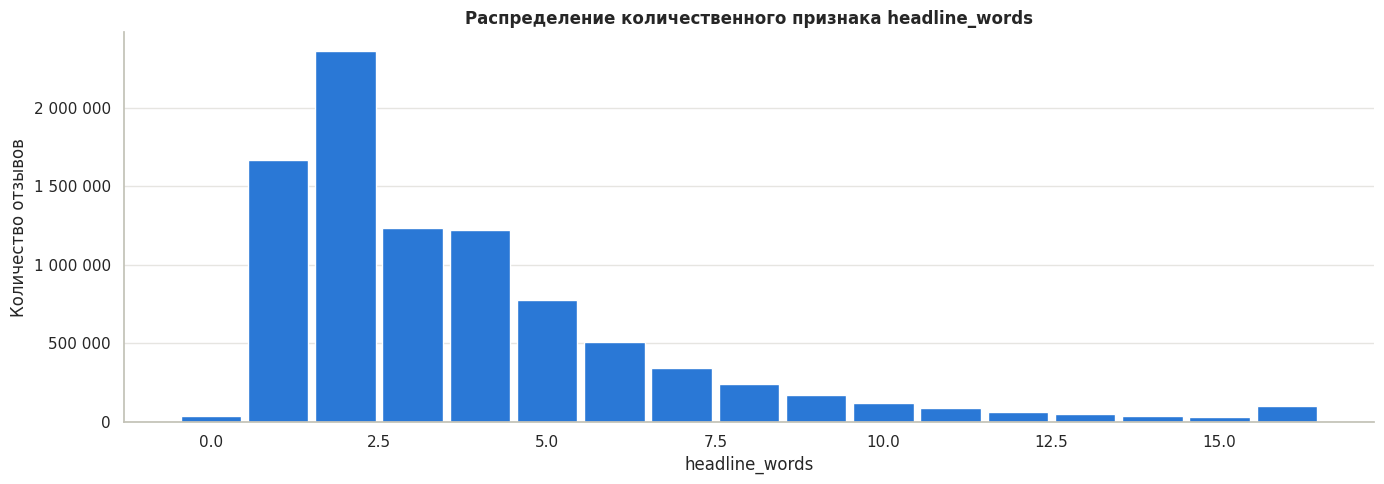

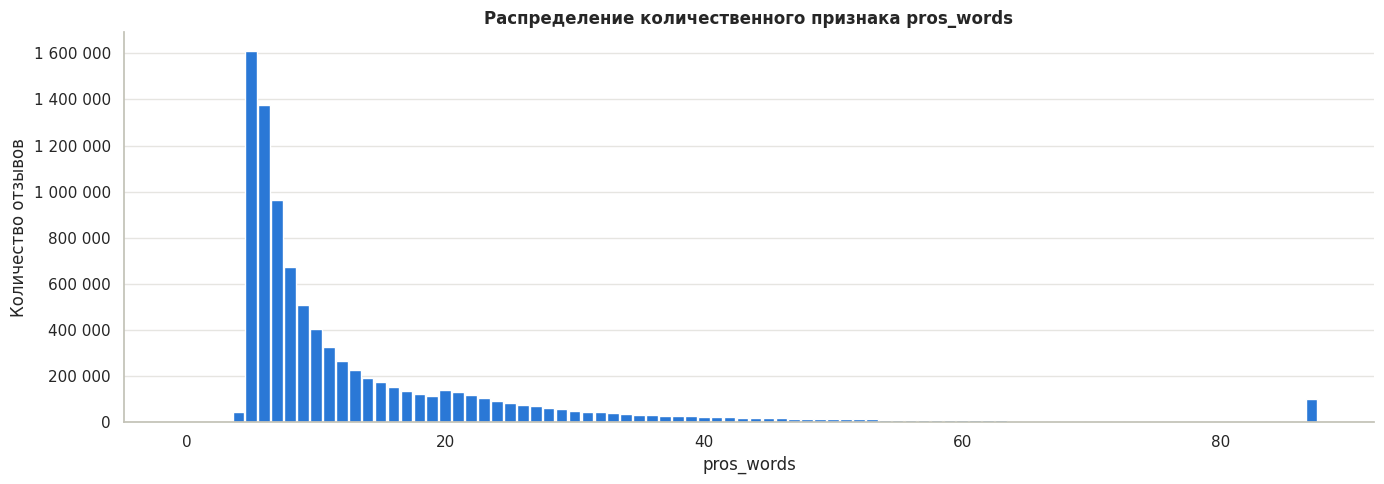

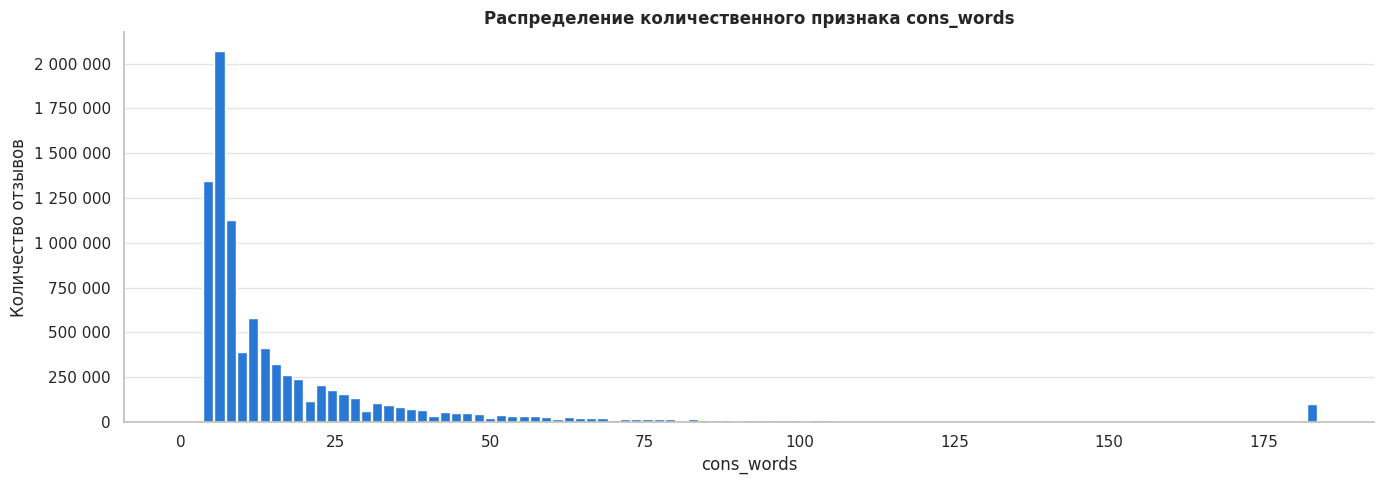

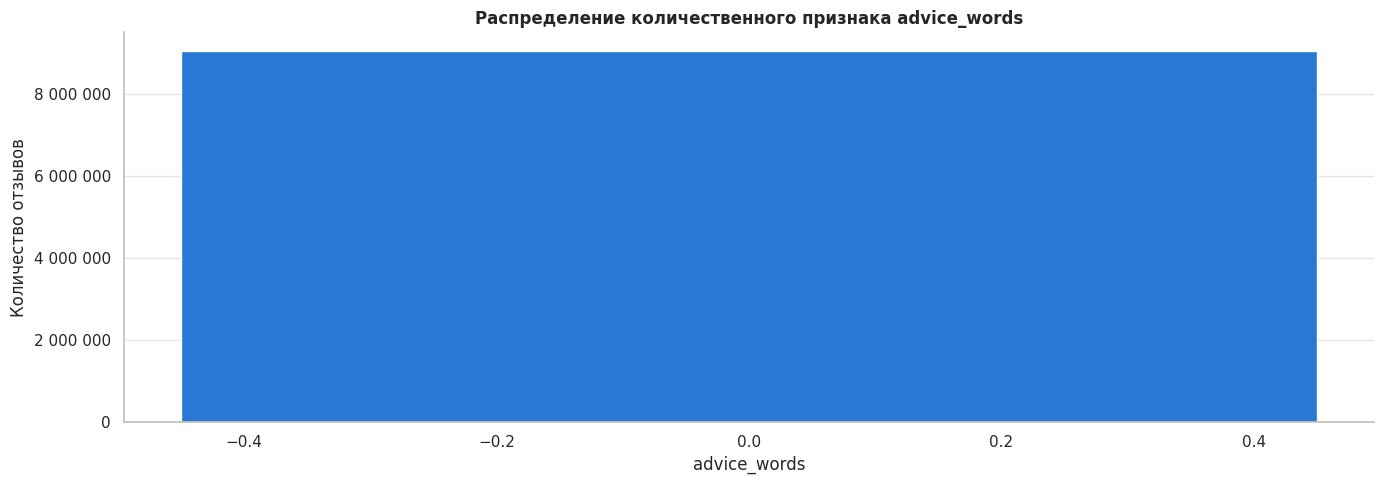

In [62]:
for column in WORD_COLUMNS:
    plot_quant_distribution(data=df, column=column)

#### 5. Статистические показатели признаков

Все преобразования выполнены. Закэшируем обработанный датафрейм, чтобы итоговые расчёты не повторяли всю цепочку преобразований.


In [63]:
df_processed = df.cache()
rows_processed = df_processed.count()
df_dedup.unpersist()
df = df_processed
rows_processed

9055084

Выведем сводную таблицу статистических показателей количественных признаков: количество значений, среднее, среднеквадратичное отклонение, минимум, квартили и максимум. Метод `summary` вычисляет их за один проход по данным; квартили рассчитываются приближённо.

In [64]:
NUMERIC_COLUMNS = [c for c, t in df.dtypes if t in ("int", "bigint", "double", "float")]

numeric_summary = (
    df
    .select(NUMERIC_COLUMNS)
    .summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max")
    .toPandas()
    .set_index("summary")
    .T
    .astype(float)
    .round(2)
)
numeric_summary

summary,count,mean,stddev,min,25%,50%,75%,max
tenure_years,9055084.0,2.10,2.49,0.0,1.0,1.0,3.0,10.0
overall_rating,9055084.0,3.55,1.25,1.0,3.0,4.0,5.0,5.0
career_opp,9055084.0,3.27,1.20,1.0,3.0,3.0,4.0,5.0
comp_benefits,9055084.0,3.28,1.14,1.0,3.0,3.0,4.0,5.0
senior_mgmt,9055084.0,3.07,1.25,1.0,2.0,3.0,4.0,5.0
work_life_balance,9055084.0,3.49,1.24,1.0,3.0,4.0,4.0,5.0
culture_values,9055084.0,3.59,1.24,1.0,3.0,4.0,4.0,5.0
headline_words,9055084.0,3.76,2.95,0.0,2.0,3.0,5.0,16.0
pros_words,9055084.0,13.91,14.24,0.0,6.0,8.0,16.0,87.0
cons_words,9055084.0,20.26,28.79,0.0,6.0,9.0,21.0,182.0


Для категориальных признаков выведем число категорий, моду (самое частое значение) и её долю.

In [65]:
def categorical_summary(data: DataFrame, columns: list[str]) -> pd.DataFrame:
    """
    Сводная таблица по категориальным признакам: число категорий,
    мода и доля моды.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        columns (list[str]): Список категориальных признаков.

    Returns:
        pd.DataFrame: Сводная таблица.
    """
    total = data.count()
    distinct = data.agg(*[F.approx_count_distinct(c).alias(c) for c in columns]).first()
    rows = []
    for column in columns:
        top = data.groupBy(column).count().orderBy(F.desc("count")).first()
        rows.append({
            "Признак": column,
            "Категорий (≈)": distinct[column],
            "Мода": top[column],
            "Доля моды, %": round(100 * top["count"] / total, 2),
        })
    return pd.DataFrame(rows).set_index("Признак")

In [66]:
CATEGORICAL_COLUMNS = [c for c, t in df.dtypes if t == "string"]
categorical_summary(data=df, columns=CATEGORICAL_COLUMNS)

,Категорий (≈),Мода,"Доля моды, %"
Признак,,,
firm,33128,Amazon,1.49
job_title,458094,Unknown,24.26
employee_status,3,Current,57.59
recommend,3,Positive,46.45
ceo_approv,4,No opinion,38.06
outlook,4,No opinion,35.55
tenure_group,7,Unknown,39.84


#### Корреляции между признаками

##### Влияние заполнения пропусков

Вычислим корреляции оценок после обработки данных и сравним коэффициенты корреляции подоценок с общей оценкой до и после заполнения пропусков.

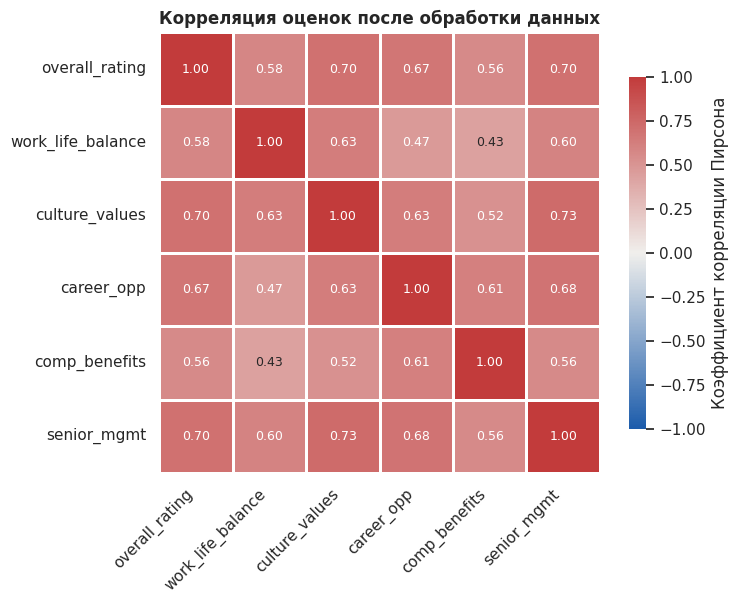

In [67]:
rating_columns_left = [c for c in RATING_COLUMNS if c in df.columns]

corr_after = compute_and_visualize_correlation_matrix(
    data=df, columns=rating_columns_left,
    title="Корреляция оценок после обработки данных"
)

In [68]:
def plot_correlation_shift(before: pd.DataFrame,
                           after: pd.DataFrame,
                           target: str = "overall_rating") -> None:
    """
    Сравнение коэффициентов корреляции признаков с целевым признаком
    до и после обработки данных.

    Args:
        before (pd.DataFrame): Корреляционная матрица до обработки.
        after (pd.DataFrame): Корреляционная матрица после обработки.
        target (str): Целевой признак.

    Returns:
        None
    """
    columns = [c for c in after.columns if c != target and c in before.columns]
    comparison = pd.DataFrame({
        "До заполнения": before.loc[columns, target],
        "После заполнения": after.loc[columns, target],
    })
    comparison["Изменение"] = comparison["После заполнения"] - comparison["До заполнения"]

    y = np.arange(len(columns))
    height = 0.38
    fig, ax = plt.subplots(figsize=(10, 0.8 * len(columns) + 1.5))
    ax.barh(y - height / 2 - 0.01, comparison["До заполнения"], height=height,
            color=MAIN_COLOR, label="До заполнения пропусков")
    ax.barh(y + height / 2 + 0.01, comparison["После заполнения"], height=height,
            color=SECOND_COLOR, label="После заполнения пропусков")
    ax.set_yticks(y)
    ax.set_yticklabels(columns)
    ax.set_xlim(min(0, comparison[["До заполнения", "После заполнения"]].min().min()), 1)
    ax.set_xlabel(f"Коэффициент корреляции с {target}")
    ax.set_title(f"Корреляция подоценок с {target} до и после заполнения пропусков")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()
    display(comparison.round(3))

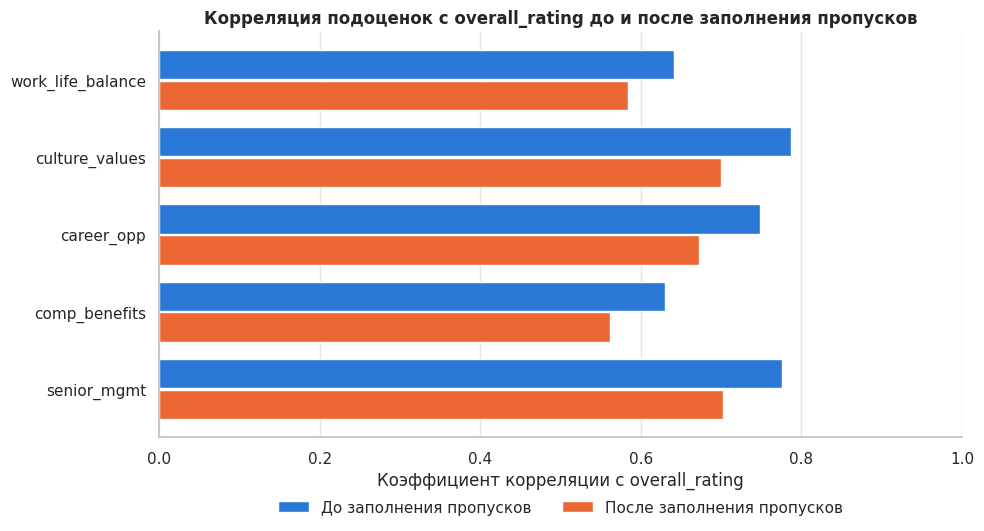

,До заполнения,После заполнения,Изменение
work_life_balance,0.642,0.584,-0.058
culture_values,0.787,0.700,-0.086
career_opp,0.748,0.673,-0.075
comp_benefits,0.631,0.562,-0.069
senior_mgmt,0.775,0.702,-0.073


In [69]:
plot_correlation_shift(before=corr_before, after=corr_after)

Заполнение константой (медианой) ослабляет корреляцию: у заполненных строк подоценка одинакова при любой общей оценке. Чем больше доля пропусков в признаке, тем сильнее снижается коэффициент.

##### Корреляции между всеми количественными признаками

Для расчёта корреляций закодируем категориальные признаки с естественным порядком числами. Мнения `recommend`, `ceo_approv`, `outlook`: `Positive` = 1, `Mild` = 0, `Negative` = −1; категории `No opinion` и `Unknown` получают `NULL` и в расчёте корреляции не участвуют. Статус сотрудника: `Current` = 1, `Former` = 0. Закодированные признаки нужны только для расчёта корреляций, поэтому в основной датафрейм не добавляются.

In [70]:
def opinion_score(column_name: str):
    """
    Возвращает выражение, кодирующее мнение числом:
    Positive = 1, Mild = 0, Negative = -1, остальные значения = NULL.
    """
    c = col(column_name)
    return (
        F.when(c == "Positive", 1)
        .when(c == "Mild", 0)
        .when(c == "Negative", -1)
    )

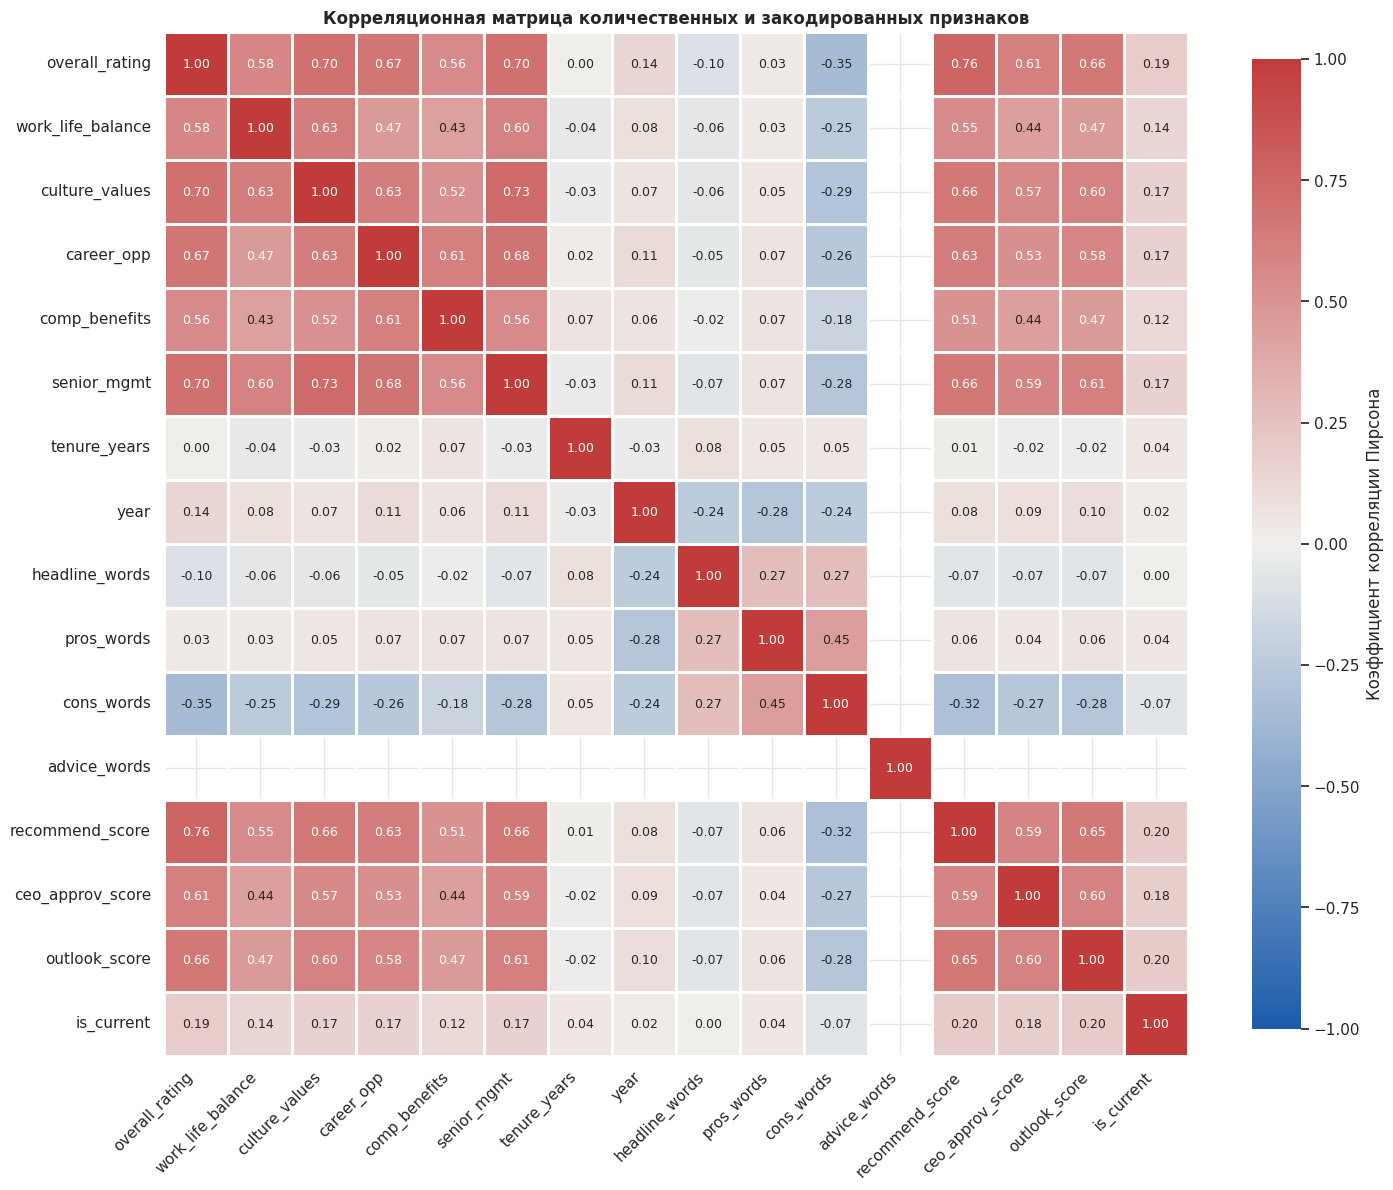

In [71]:
QUANTITATIVE_COLUMNS = [
    c for c in rating_columns_left
    + ["tenure_years", "year", "headline_words", "pros_words", "cons_words",
       "advice_words"]
    if c in df.columns
]

corr_data = df.select(
    *QUANTITATIVE_COLUMNS,
    *[opinion_score(c).alias(f"{c}_score") for c in OPINION_COLUMNS],
    F.when(col("employee_status") == "Current", 1)
     .when(col("employee_status") == "Former", 0)
     .alias("is_current"),
)

corr_full = compute_and_visualize_correlation_matrix(
    data=corr_data, columns=corr_data.columns,
    title="Корреляционная матрица количественных и закодированных признаков"
)

Отдельно выведем связь всех признаков с целевым признаком `overall_rating`, упорядочив их по силе связи

In [72]:
def plot_target_correlations(matrix: pd.DataFrame,
                             target: str = "overall_rating") -> None:
    """
    Построение коэффициентов корреляции всех признаков с целевым
    признаком, упорядоченных по абсолютному значению.

    Args:
        matrix (pd.DataFrame): Корреляционная матрица.
        target (str): Целевой признак.

    Returns:
        None
    """
    values = matrix[target].drop(target).dropna().round(2) + 0.0
    values = values.reindex(values.abs().sort_values().index)
    colors = [MAIN_COLOR if v >= 0 else NEGATIVE_COLOR for v in values]

    fig, ax = plt.subplots(figsize=(10, 0.45 * len(values) + 1.5))
    ax.barh(values.index, values, color=colors, height=0.6)
    for y, value in enumerate(values):
        offset = 0.02 if value >= 0 else -0.02
        ax.text(value + offset, y, f"{value:.2f}", va="center",
                ha="left" if value >= 0 else "right",
                fontsize=9, color=TEXT_COLOR)
    ax.axvline(0, color="#c3c2b7", linewidth=1)
    ax.set_xlim(min(-0.1, values.min() - 0.15), 1.05)
    ax.set_xlabel(f"Коэффициент корреляции с {target}")
    ax.set_title(f"Связь признаков с {target}")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()

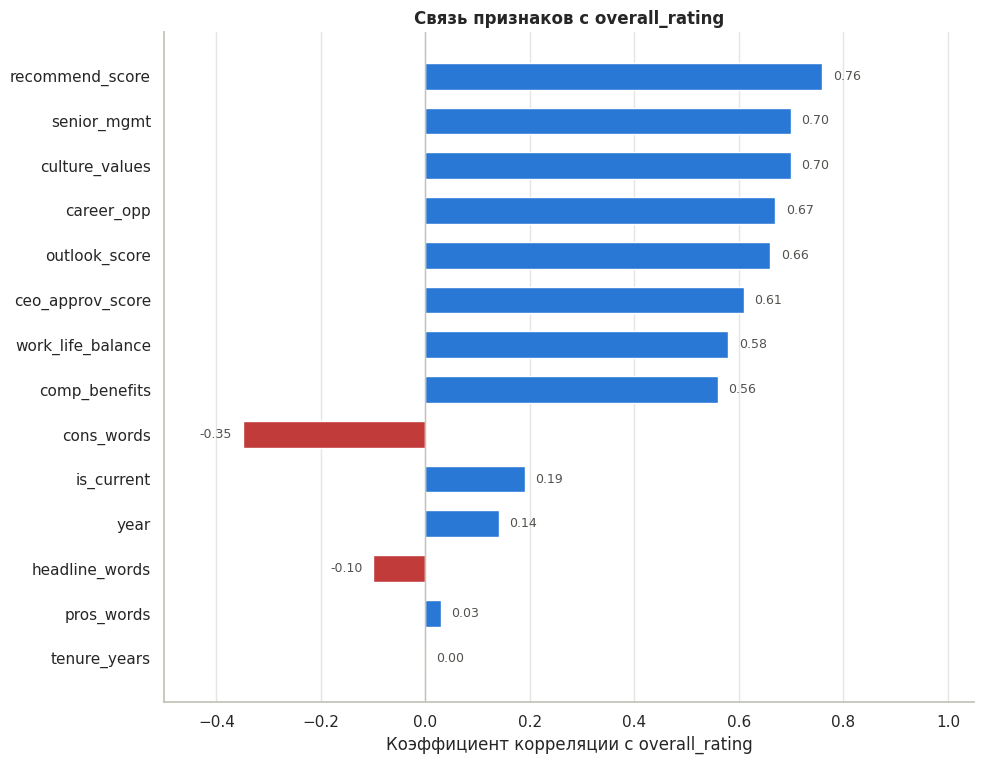

In [73]:
plot_target_correlations(matrix=corr_full)

In [74]:
plot_null_report(null_report(df))

Пропущенных значений нет


In [75]:
print(f"Строк в исходной таблице:   {rows_initial}")
print(f"Строк после обработки:      {rows_processed}")
print(f"Удалено строк:              {rows_initial - rows_processed} "
      f"({100 * (rows_initial - rows_processed) / rows_initial:.2f}%)")

Строк в исходной таблице:   9901889
Строк после обработки:      9055084
Удалено строк:              846805 (8.55%)


In [76]:
df.printSchema()

root
 |-- firm: string (nullable = true)
 |-- date_review: date (nullable = true)
 |-- job_title: string (nullable = false)
 |-- employee_status: string (nullable = false)
 |-- tenure_years: integer (nullable = true)
 |-- overall_rating: integer (nullable = true)
 |-- recommend: string (nullable = false)
 |-- ceo_approv: string (nullable = false)
 |-- outlook: string (nullable = false)
 |-- career_opp: double (nullable = false)
 |-- comp_benefits: double (nullable = false)
 |-- senior_mgmt: double (nullable = false)
 |-- work_life_balance: double (nullable = false)
 |-- culture_values: double (nullable = false)
 |-- headline_words: integer (nullable = false)
 |-- pros_words: integer (nullable = false)
 |-- cons_words: integer (nullable = false)
 |-- advice_words: integer (nullable = false)
 |-- year: integer (nullable = true)
 |-- tenure_group: string (nullable = true)



In [77]:
df.show(5)

+--------------------+-----------+--------------------+---------------+------------+--------------+----------+----------+----------+----------+-------------+-----------+-----------------+--------------+--------------+----------+----------+------------+----+------------+
|                firm|date_review|           job_title|employee_status|tenure_years|overall_rating| recommend|ceo_approv|   outlook|career_opp|comp_benefits|senior_mgmt|work_life_balance|culture_values|headline_words|pros_words|cons_words|advice_words|year|tenure_group|
+--------------------+-----------+--------------------+---------------+------------+--------------+----------+----------+----------+----------+-------------+-----------+-----------------+--------------+--------------+----------+----------+------------+----+------------+
|             Walmart| 2019-05-11|    Staff Pharmacist|         Former|          10|             3|  Negative|      Mild|  Positive|       4.0|          4.0|        2.0|              3.0|

In [78]:
df.writeTo("glassdoor_reviews_processed").using("iceberg").createOrReplace()

26/10/10 16:05:26 WARN HadoopTableOperations: Error reading version hint file hdfs:/user/user0/warehouse/orlov_database/glassdoor_reviews_processed/metadata/version-hint.text
java.io.FileNotFoundException: File does not exist: /user/user0/warehouse/orlov_database/glassdoor_reviews_processed/metadata/version-hint.text
	at org.apache.hadoop.hdfs.server.namenode.INodeFile.valueOf(INodeFile.java:87)
	at org.apache.hadoop.hdfs.server.namenode.INodeFile.valueOf(INodeFile.java:77)
	at org.apache.hadoop.hdfs.server.namenode.FSDirStatAndListingOp.getBlockLocations(FSDirStatAndListingOp.java:159)
	at org.apache.hadoop.hdfs.server.namenode.FSNamesystem.getBlockLocations(FSNamesystem.java:2198)
	at org.apache.hadoop.hdfs.server.namenode.NameNodeRpcServer.getBlockLocations(NameNodeRpcServer.java:795)
	at org.apache.hadoop.hdfs.protocolPB.ClientNamenodeProtocolServerSideTranslatorPB.getBlockLocations(ClientNamenodeProtocolServerSideTranslatorPB.java:468)
	at org.apache.hadoop.hdfs.protocol.proto.Cli

In [79]:
for table in spark.catalog.listTables():
    print(table.name)

glassdoor_reviews
glassdoor_reviews_processed
sobd_lab1_table
sobd_lab1_processed_table


In [80]:
df.unpersist()
spark.stop()